# Web Scraping Menggunakan API Google Books

## Library yang dibutuhkan

In [ ]:
%pip install requests==2.32.3 pandas==2.2.3 numpy==2.2.6 scipy==1.15.3 scikit-learn==1.6.1 matplotlib==3.10.3 gensim==4.4.0 umap-learn==0.5.9.post2 numba==0.61.2 joblib==1.4.2 nltk==3.10.3 plotly==7.1.0 beautifulsoup4 Sastrawi demoji wordcloud ipython ipykernel jupyterlab ipywidgets


In [ ]:
import requests
import json
import pandas as pd


## 1. Request ke Google Books API

In [ ]:
query = 'Laskar Pelangi Andrea Hirata'
api_key = 'GOOGLE BOOK API KEY'

api_url = 'https://www.googleapis.com/books/v1/volumes'
params = {'q': query, 'maxResults': 1, 'key': api_key}

response = requests.get(api_url, params=params, timeout=30)

print('Status code:', response.status_code)

data = response.json()

if response.status_code != 200 or 'error' in data:
    raise RuntimeError(data.get('error', {}).get('message', 'Google Books API gagal'))
if not data.get('items'):
    raise ValueError('Tidak ada buku yang ditemukan untuk query ini.')


Status code: 200


## 2. Melihat struktur mentah JSON

In [ ]:
item = data['items'][0]
print(json.dumps(item, indent=2, ensure_ascii=False)[:1500])


{
  "kind": "books#volume",
  "id": "S0ZNe2iqM54C",
  "etag": "s7u/fqULtvk",
  "selfLink": "https://www.googleapis.com/books/v1/volumes/S0ZNe2iqM54C",
  "volumeInfo": {
    "title": "Laskar Pelangi",
    "authors": [
      "Andrea Hirata"
    ],
    "publisher": "Bentang Pustaka",
    "publishedDate": "2008",
    "description": "Laskar Pelangi telah menjadi international best seller, diterjemahkan ke dalam 40 bahasa asing. Telah terbit dalam 22 bahasa, diedarkan di lebih dari 130 negara. Melalui program beasiswa, Hirata meraih Master of Science (M.Sc.) bidang teori ekonomi dari Sheffield Hallam University, UK. Hirata juga mendapat beasiswa pendidikan sastra di IWP (International Writing Program), University of Iowa, USA.",
    "industryIdentifiers": [
      {
        "type": "ISBN_10",
        "identifier": "9793062797"
      },
      {
        "type": "ISBN_13",
        "identifier": "9789793062792"
      }
    ],
    "readingModes": {
      "text": false,
      "image": false
    },


## 3. Ekstraksi field penting

In [ ]:
volume_info = item.get('volumeInfo', {})

book_id = item.get('id')
title = volume_info.get('title')
authors = volume_info.get('authors')
description = volume_info.get('description')
rating = volume_info.get('averageRating')
ratings_count = volume_info.get('ratingsCount')
page_count = volume_info.get('pageCount')
categories = volume_info.get('categories')
published_date = volume_info.get('publishedDate')
info_link = volume_info.get('infoLink')

print('Book ID         :', book_id)
print('Judul           :', title)
print('Penulis         :', authors)
print('Terbit          :', published_date)
print('Kategori        :', categories)
print('Jumlah halaman  :', page_count)
print('Rating          :', rating, '- dari', ratings_count, 'penilaian')
print('Link            :', info_link)
print()
print('Deskripsi       :', description)


Book ID         : S0ZNe2iqM54C
Judul           : Laskar Pelangi
Penulis         : ['Andrea Hirata']
Terbit          : 2008
Kategori        : ['Indonesian fiction']
Jumlah halaman  : 556
Rating          : 4.5 - dari 99 penilaian
Link            : http://books.google.co.id/books?id=S0ZNe2iqM54C&dq=Laskar+Pelangi+Andrea+Hirata&hl=&source=gbs_api

Deskripsi       : Laskar Pelangi telah menjadi international best seller, diterjemahkan ke dalam 40 bahasa asing. Telah terbit dalam 22 bahasa, diedarkan di lebih dari 130 negara. Melalui program beasiswa, Hirata meraih Master of Science (M.Sc.) bidang teori ekonomi dari Sheffield Hallam University, UK. Hirata juga mendapat beasiswa pendidikan sastra di IWP (International Writing Program), University of Iowa, USA.


## 4. Mengambil beberapa buku sekaligus

In [ ]:
params_multi = {'q': query, 'maxResults': 10, 'key': api_key}
response_multi = requests.get(api_url, params=params_multi, timeout=30)
data_multi = response_multi.json()
if response_multi.status_code != 200 or 'error' in data_multi:
    raise RuntimeError(data_multi.get('error', {}).get('message', 'Google Books API gagal'))

records = []
for it in data_multi.get('items', []):
    vi = it.get('volumeInfo', {})
    records.append({
        'id': it.get('id'),
        'judul': vi.get('title'),
        'penulis': vi.get('authors'),
        'deskripsi': vi.get('description'),
        'bahasa_buku': vi.get('language'),
        'rating': vi.get('averageRating'),
        'jumlah_rating': vi.get('ratingsCount'),
        'kategori': vi.get('categories'),
        'terbit': vi.get('publishedDate')
    })

print('Jumlah buku ditemukan:', len(records))


Jumlah buku ditemukan: 10


## 5. Membuat DataFrame

In [ ]:
df = pd.DataFrame(records, columns=[
    'id', 'judul', 'penulis', 'deskripsi', 'bahasa_buku',
    'rating', 'jumlah_rating', 'kategori', 'terbit'
])
df


,id,judul,penulis,deskripsi,bahasa_buku,rating,jumlah_rating,kategori,terbit
0,S0ZNe2iqM54C,Laskar Pelangi,[Andrea Hirata],Laskar Pelangi telah menjadi international bes...,id,4.5,99.0,[Indonesian fiction],2008
1,8JTTDwAAQBAJ,"Andrea Hirata, Laskar Pelangi - dalam Novel da...",[TEMPO Publishing],"Setelah novel Andrea Hirata meledak, kini sutr...",id,NaN,NaN,[Biography & Autobiography],2020-01-01
2,8InjVEJ9WD0C,Teori dan kritikan sastera,[Sohaimi Abdul Aziz],History and criticism on Malay literature.,ms,NaN,NaN,[Malay literature],2014
3,h_284i9CBlcC,Dewa Ruci,None,NaN,id,NaN,NaN,[Arts],2011
4,z4kKAQAAMAAJ,Mingguan hidup,None,NaN,id,NaN,NaN,[Church and social problems],2008
5,CXGO0HfSJ5UC,Warisan geologi Pulau Belitung,[Oki Oktariadi],"Geology of Belitung Island, Indonesia.",id,NaN,NaN,[Billiton Island (Indonesia)],2014
6,nJegcEQYtcUC,Istoriografii͡a i istochnikovedenie istorii st...,None,NaN,ru,NaN,NaN,[Africa],2011
7,TAf2hP1jsxQC,Fasilitator,None,On kindergarten and primary education in Indon...,id,NaN,NaN,"[Education, Primary]",2008
8,1kSgHfLXUp8C,Bahasa & sastra Indonesia,None,On Indonesian language and literature; papers ...,id,NaN,NaN,[Indonesia],2011
9,lVv0iyK0eEMC,MEAsia,None,NaN,id,NaN,NaN,None,2014


## Text Processing - Chapter 4

,judul,status_processing,bahasa_deskripsi,text,prepro,token_sebelum,token_setelah
0,Laskar Pelangi,diproses,id,Laskar Pelangi telah menjadi international bes...,laskar pelangi international best seller terje...,56,40
1,"Andrea Hirata, Laskar Pelangi - dalam Novel da...",diproses,id,"Setelah novel Andrea Hirata meledak, kini sutr...",novel andrea hirata ledak sutradara riri riza ...,59,44
2,Teori dan kritikan sastera,diproses,en,History and criticism on Malay literature.,histori critic malay literatur,6,4
3,Dewa Ruci,deskripsi kosong - dilewati,kosong,,,0,0
4,Mingguan hidup,deskripsi kosong - dilewati,kosong,,,0,0
5,Warisan geologi Pulau Belitung,diproses,en,"Geology of Belitung Island, Indonesia.",geolog belitung island indonesia,5,4
6,Istoriografii͡a i istochnikovedenie istorii st...,deskripsi kosong - dilewati,kosong,,,0,0
7,Fasilitator,diproses,en,On kindergarten and primary education in Indon...,kindergarten primari educ indonesia,7,4
8,Bahasa & sastra Indonesia,diproses,en,On Indonesian language and literature; papers ...,indonesian languag literatur paper seminar,9,5
9,MEAsia,deskripsi kosong - dilewati,kosong,,,0,0


,judul,clean_text,rm_stopwords,stem,lemma_en,rm_frequent_demo,rm_rare_demo
0,Laskar Pelangi,laskar pelangi telah menjadi international bes...,laskar pelangi international best seller diter...,laskar pelangi international best seller terje...,,pelangi international best seller diterjemahka...,laskar pelangi international bahasa bahasa pro...
1,"Andrea Hirata, Laskar Pelangi - dalam Novel da...",setelah novel andrea hirata meledak kini sutra...,novel andrea hirata meledak sutradara riri riz...,novel andrea hirata ledak sutradara riri riza ...,,novel andrea meledak sutradara riri riza menco...,hirata riri riza laskar pelangi belitung belit...
2,Teori dan kritikan sastera,history and criticism on malay literature,history criticism malay literature,histori critic malay literatur,history criticism malay literature,history criticism malay,literature
3,Dewa Ruci,,,,,,
4,Mingguan hidup,,,,,,
5,Warisan geologi Pulau Belitung,geology of belitung island indonesia,geology belitung island indonesia,geolog belitung island indonesia,geology belitung island indonesia,geology island,indonesia
6,Istoriografii͡a i istochnikovedenie istorii st...,,,,,,
7,Fasilitator,on kindergarten and primary education in indon...,kindergarten primary education indonesia,kindergarten primari educ indonesia,kindergarten primary education indonesia,kindergarten primary education,indonesia
8,Bahasa & sastra Indonesia,on indonesian language and literature papers o...,indonesian language literature papers seminar,indonesian languag literatur paper seminar,indonesian language literature paper seminar,indonesian language papers seminar,literature
9,MEAsia,,,,,,


Record sumber: 10
Deskripsi tersedia: 6
Deskripsi kosong: 4
Deskripsi unik: 6


,bahasa,kata,frekuensi
0,en,indonesia,2
1,en,literature,2
2,en,belitung,1
3,en,criticism,1
4,en,education,1
5,en,geology,1
6,en,history,1
7,en,indonesian,1
8,en,island,1
9,en,kindergarten,1


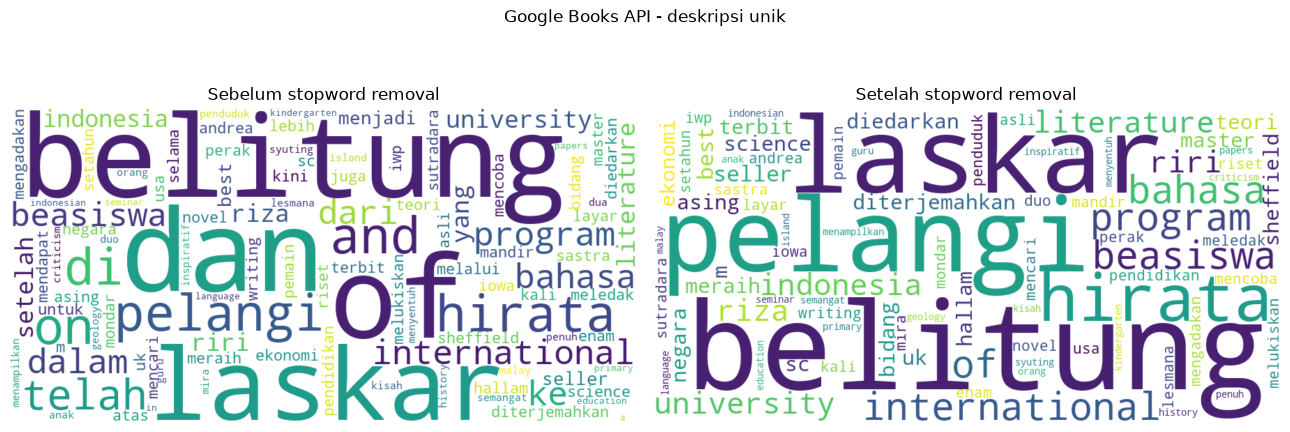

CSV hasil tersimpan: hasil_text_processing_api


In [ ]:
# Seluruh proses Chapter 4 dijadikan satu blok dan memakai df hasil scraping di atas.
from pathlib import Path
from collections import Counter
import os
import re
import json
import unicodedata
import pandas as pd
from bs4 import BeautifulSoup
import demoji
import nltk
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, WordNetLemmatizer
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from IPython.display import display

METHOD = 'API'
output_dir = Path.cwd() / ('hasil_text_processing_' + METHOD.lower())
output_dir.mkdir(exist_ok=True)
def prepare_nltk_data(base_dir, resource_names):
    from pathlib import Path
    from io import BytesIO
    import hashlib
    import zipfile
    import requests
    import nltk
    from requests.adapters import HTTPAdapter
    from urllib3.util.retry import Retry

    packages = {
        'stopwords': ('corpora', 'corpora/stopwords', '48c0e52d8b52546e827f53761fb30300c0ab94f70660d28bd65ba0a86270946b'),
        'wordnet': ('corpora', 'corpora/wordnet.zip', 'cbda5ea6eef7f36a97a43d4a75f85e07fccbb4f23657d27b4ccbc93e2646ab59'),
        'averaged_perceptron_tagger_eng': ('taggers', 'taggers/averaged_perceptron_tagger_eng', '6025f530624335c67d6547d44757b357b4e79bae030a0383e9887a92c1718f0b'),
        'punkt_tab': ('tokenizers', 'tokenizers/punkt_tab/english', 'e57f64187974277726a3417ca6f181ec5403676c717672eef6a748a7b20e0106'),
    }
    candidates = [base_dir / 'nltk_data', base_dir / 'web_scraping_google_books-main' / 'nltk_data',
                  base_dir.parent / 'nltk_data', base_dir / '.nltk_data']
    data_dir = next((p.resolve() for p in candidates if p.is_dir()), (base_dir / '.nltk_data').resolve())
    data_dir.mkdir(parents=True, exist_ok=True)
    if str(data_dir) not in nltk.data.path:
        nltk.data.path.insert(0, str(data_dir))
    retry = Retry(total=3, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504], allowed_methods=['GET'])
    with requests.Session() as session:
        session.mount('https://', HTTPAdapter(max_retries=retry))
        for name in resource_names:
            category, locator, expected_sha = packages[name]
            try:
                nltk.data.find(locator, paths=[str(data_dir)])
                continue
            except LookupError:
                pass
            url = 'https://raw.githubusercontent.com/nltk/nltk_data/550b6625bcef1f2abff2ff770a5a0d272c9c6b2a/packages/' + category + '/' + name + '.zip'
            payload = bytearray()
            with session.get(url, timeout=(15, 120), stream=True, allow_redirects=False) as response:
                if response.status_code != 200:
                    raise RuntimeError('Unduhan resource NLTK gagal: ' + name + ' (HTTP ' + str(response.status_code) + '). Coba ulang cell ini.')
                for chunk in response.iter_content(1024 * 1024):
                    payload.extend(chunk)
                    if len(payload) > 50 * 1024 * 1024:
                        raise RuntimeError('Arsip resource NLTK terlalu besar: ' + name)
            if hashlib.sha256(payload).hexdigest() != expected_sha:
                raise RuntimeError('Checksum resource NLTK tidak cocok: ' + name)
            archive_bytes = bytes(payload)
            with zipfile.ZipFile(BytesIO(archive_bytes)) as archive:
                if archive.testzip() is not None:
                    raise RuntimeError('Arsip resource NLTK rusak: ' + name)
                members = [info for info in archive.infolist() if not info.is_dir()]
                if sum(info.file_size for info in members) > 200 * 1024 * 1024:
                    raise RuntimeError('Isi resource NLTK terlalu besar: ' + name)
                destinations = [(info, (data_dir / category / info.filename).resolve()) for info in members]
                if any(not dest.is_relative_to(data_dir / category) or
                       (info.external_attr >> 16) & 0o170000 == 0o120000
                       for info, dest in destinations):
                    raise RuntimeError('Path arsip resource NLTK tidak valid: ' + name)
                if name == 'wordnet':
                    target = data_dir / category / (name + '.zip')
                    target.parent.mkdir(parents=True, exist_ok=True)
                    target.write_bytes(archive_bytes)
                else:
                    for info, dest in destinations:
                        if name == 'stopwords' and info.filename not in ['stopwords/english', 'stopwords/indonesian', 'stopwords/README']:
                            continue
                        if name == 'punkt_tab' and not (info.filename.startswith('punkt_tab/english/') or info.filename == 'punkt_tab/README'):
                            continue
                        dest.parent.mkdir(parents=True, exist_ok=True)
                        dest.write_bytes(archive.read(info))
            nltk.data.find(locator, paths=[str(data_dir)])
    return data_dir

nltk_dir = prepare_nltk_data(Path.cwd(), ['stopwords', 'wordnet', 'averaged_perceptron_tagger_eng'])

if 'deskripsi' not in df.columns:
    raise ValueError('Jalankan scraping dan pembuatan DataFrame terlebih dahulu.')
df_processed = df.copy()
df_processed['metode'] = METHOD
df_processed['text'] = df_processed['deskripsi'].fillna('').astype(str).str.strip()
df_processed['status_processing'] = df_processed['text'].map(
    lambda value: 'diproses' if value else 'deskripsi kosong - dilewati')

def remove_html(value):
    parsed = BeautifulSoup(str(value), 'html.parser')
    for tag in parsed(['script', 'style']):
        tag.decompose()
    return unicodedata.normalize('NFKC', parsed.get_text(' ', strip=True))

def remove_urls_email(value):
    value = re.sub(r'\b(?:https?://|www\.)\S+', ' ', value)
    return re.sub(r'\b[\w.+-]+@[\w.-]+\.[a-z]{2,}\b', ' ', value, flags=re.I)

def remove_emoji_emoticon(value):
    value = demoji.replace(value, ' ')
    return re.sub(r'(?::|;|=|8)[\-^]?[)(/\\|DPpOo]+', ' ', value)

def remove_punctuation(value):
    return ''.join(' ' if unicodedata.category(char)[0] in {'P', 'S'} else char
                   for char in value)

def normalize_space(value):
    return re.sub(r'\s+', ' ', value).strip()

df_processed['rm_html'] = df_processed['text'].map(remove_html)
df_processed['rm_hashtag'] = df_processed['rm_html'].map(lambda x: re.sub(r'#\w+', ' ', x))
df_processed['lower_case'] = df_processed['rm_hashtag'].str.lower()
df_processed['rm_url_email'] = df_processed['lower_case'].map(remove_urls_email)
df_processed['rm_emoji'] = df_processed['rm_url_email'].map(remove_emoji_emoticon)
df_processed['rm_punc'] = df_processed['rm_emoji'].map(remove_punctuation)
df_processed['rm_number'] = df_processed['rm_punc'].map(lambda x: re.sub(r'\d+', ' ', x))
df_processed['clean_text'] = df_processed['rm_number'].map(normalize_space)
df_processed['tokens'] = df_processed['clean_text'].str.split()

# Bahasa buku dari API dapat berbeda dengan bahasa teks deskripsinya.
# Bandingkan kata fungsi en/id; jika tidak ada petunjuk, gunakan metadata.
sw = {language: set(stopwords.words(name)) for language, name in
      [('en', 'english'), ('id', 'indonesian')]}
negations = {'en': {'no', 'not', 'nor'}, 'id': {'tidak', 'bukan', 'belum', 'jangan'}}

def choose_language(row):
    if not row['tokens']:
        return 'kosong'
    scores = {language: sum(t in words for t in row['tokens']) for language, words in sw.items()}
    if scores['en'] > scores['id']:
        return 'en'
    if scores['id'] > scores['en']:
        return 'id'
    hint = row.get('bahasa_buku', '')
    return hint if hint in sw else 'lainnya'

df_processed['bahasa_deskripsi'] = df_processed.apply(choose_language, axis=1)
filtered_sw = {language: words - negations[language] for language, words in sw.items()}
df_processed['tokens_no_stopwords'] = df_processed.apply(
    lambda row: [t for t in row['tokens']
                 if t not in filtered_sw.get(row['bahasa_deskripsi'], set())], axis=1)
df_processed['rm_stopwords'] = df_processed['tokens_no_stopwords'].map(' '.join)
porter = PorterStemmer()
id_stemmer = StemmerFactory().create_stemmer()
lemmatizer = WordNetLemmatizer()

def stem_row(row):
    if row['bahasa_deskripsi'] == 'en':
        return ' '.join(porter.stem(t) for t in row['tokens_no_stopwords'])
    if row['bahasa_deskripsi'] == 'id':
        return id_stemmer.stem(row['rm_stopwords'])
    return row['rm_stopwords']

def lemma_row(row):
    if row['bahasa_deskripsi'] != 'en':
        return ''  # WordNet Inggris tidak diterapkan pada bahasa lain.
    mapping = {'J': wordnet.ADJ, 'V': wordnet.VERB, 'N': wordnet.NOUN, 'R': wordnet.ADV}
    lemmas = [lemmatizer.lemmatize(t, mapping.get(tag[0], wordnet.NOUN))
              for t, tag in nltk.pos_tag(row['tokens'])]
    return ' '.join(t for t in lemmas if t not in filtered_sw['en'])

df_processed['stem'] = df_processed.apply(stem_row, axis=1)
df_processed['lemma_en'] = df_processed.apply(lemma_row, axis=1)
df_processed['prepro'] = df_processed['stem']
df_processed['token_sebelum'] = df_processed['text'].map(lambda x: len(x.split()))
df_processed['token_setelah'] = df_processed['prepro'].map(lambda x: len(x.split()))

# Filter frequent/rare hanya contoh: jangan menghilangkan istilah penting pada korpus kecil.
unique = df_processed.loc[df_processed['clean_text'].ne('')].drop_duplicates('clean_text')
language_counts = {language: Counter(t for tokens in group['tokens_no_stopwords'] for t in tokens)
                   for language, group in unique.groupby('bahasa_deskripsi')}
top_words = {language: set(w for w, count in sorted(counts.items(), key=lambda x: (-x[1], x[0]))[:3])
             for language, counts in language_counts.items()}
rare_words = {language: {w for w, count in counts.items() if count == 1}
              for language, counts in language_counts.items()}
for column, word_sets in [('rm_frequent_demo', top_words), ('rm_rare_demo', rare_words)]:
    df_processed[column] = df_processed.apply(
        lambda row: ' '.join(t for t in row['tokens_no_stopwords']
                             if t not in word_sets.get(row['bahasa_deskripsi'], set())), axis=1)
freq_records = [{'bahasa': language, 'kata': word, 'frekuensi': count}
                for language, counts in language_counts.items()
                for word, count in sorted(counts.items(), key=lambda x: (-x[1], x[0]))]
df_frequency = pd.DataFrame(freq_records, columns=['bahasa', 'kata', 'frekuensi'])

display(df_processed[['judul', 'status_processing', 'bahasa_deskripsi', 'text',
                      'prepro', 'token_sebelum', 'token_setelah']])
display(df_processed[['judul', 'clean_text', 'rm_stopwords', 'stem', 'lemma_en',
                      'rm_frequent_demo', 'rm_rare_demo']])
print('Record sumber:', len(df_processed))
print('Deskripsi tersedia:', int(df_processed['text'].ne('').sum()))
print('Deskripsi kosong:', int(df_processed['text'].eq('').sum()))
print('Deskripsi unik:', len(unique))
display(df_frequency.head(15))

before = Counter(t for tokens in unique['tokens'] for t in tokens)
after = Counter(t for tokens in unique['tokens_no_stopwords'] for t in tokens)
if after:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for ax, counts, label in zip(axes, [before, after],
                                ['Sebelum stopword removal', 'Setelah stopword removal']):
        cloud = WordCloud(width=900, height=450, background_color='white',
                          random_state=42, collocations=False).generate_from_frequencies(counts)
        ax.imshow(cloud, interpolation='bilinear')
        ax.set_title(label)
        ax.axis('off')
    fig.suptitle('Google Books ' + METHOD + ' - deskripsi unik')
    fig.tight_layout()
    fig.savefig(output_dir / 'wordcloud.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('Tidak ada token untuk visualisasi.')

export = df_processed.copy()
for column in ['tokens', 'tokens_no_stopwords']:
    export[column] = export[column].map(lambda tokens: json.dumps(tokens, ensure_ascii=False))
export.to_csv(output_dir / ('google_books_' + METHOD.lower() + '_preprocessed.csv'),
              index=False, encoding='utf-8-sig')
df_frequency.to_csv(output_dir / 'frekuensi_kata.csv', index=False, encoding='utf-8-sig')
print('CSV hasil tersimpan:', output_dir.name)


## Exercise 5 — Feature Engineering API

In [ ]:
import warnings
warnings.filterwarnings('ignore', message=r'^IProgress not found\..*',
                        category=Warning, module=r'^tqdm\.(auto|autonotebook)$')
from pathlib import Path
from datetime import datetime, timezone
import os, json, hashlib, importlib.metadata as im
import pandas as pd
import numpy as np
import nltk
from nltk import word_tokenize
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from scipy import sparse
from gensim.models import Word2Vec, FastText
from umap import UMAP
import plotly.express as px
import joblib
from IPython.display import display

DATA_ROOT = Path.cwd()
EXERCISE_SOURCE = 'API'
REQUIRED = {'requests': '2.32.3', 'pandas': '2.2.3', 'numpy': '2.2.6', 'scipy': '1.15.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.3', 'gensim': '4.4.0', 'umap-learn': '0.5.9.post2', 'numba': '0.61.2', 'joblib': '1.4.2', 'nltk': '3.10.3', 'plotly': '7.1.0'}


### 1. Data preprocessing

In [ ]:
input_mode = 'csv_snapshot'
source_frame = None
if 'df_processed' in globals() and isinstance(df_processed, pd.DataFrame) and 'prepro' in df_processed:
    methods = set(df_processed.get('metode', pd.Series(dtype=str)).dropna().astype(str).str.upper()) - {''}
    if not methods or methods == {EXERCISE_SOURCE}:
        source_frame = df_processed.copy(deep=True)
        input_mode = 'in_memory_Chapter4'
snapshot = None
if source_frame is None:
    name = 'google_books_' + EXERCISE_SOURCE.lower() + '_preprocessed.csv'
    original_folder = 'API_pre-processing_result' if EXERCISE_SOURCE == 'API' else 'Http_pre-processing_result'
    candidates = [DATA_ROOT / ('hasil_text_processing_' + EXERCISE_SOURCE.lower()) / name,
                  DATA_ROOT / original_folder / name, DATA_ROOT / name]
    snapshot = next((p for p in candidates if p.is_file()), None)
    if snapshot is None:
        matches = sorted(DATA_ROOT.glob('**/' + name))
        snapshot = matches[0] if matches else None
    if snapshot is None:
        raise FileNotFoundError('Jalankan cell preprocessing ' + EXERCISE_SOURCE + ' terlebih dahulu, atau gunakan CSV dari ZIP lengkap.')
    source_frame = pd.read_csv(snapshot, keep_default_na=False, encoding='utf-8-sig')
    if snapshot.parent.name in [original_folder, 'hasil_text_processing_' + EXERCISE_SOURCE.lower()]:
        DATA_ROOT = snapshot.parent.parent
if 'prepro' not in source_frame:
    raise ValueError('Data sumber harus memiliki kolom prepro.')
RESULT = DATA_ROOT / 'feature_engineering_result' / EXERCISE_SOURCE
RESULT.mkdir(parents=True, exist_ok=True)
source_frame['prepro'] = source_frame['prepro'].fillna('').astype(str).str.strip()
source_frame['source_row'] = np.arange(1, len(source_frame) + 1)
corpus = source_frame.loc[source_frame['prepro'].ne('')].copy().reset_index(drop=True)
if corpus.empty:
    raise ValueError('Tidak ada hasil preprocessing yang dapat digunakan.')
for column in ['id', 'judul']:
    if column not in corpus:
        corpus[column] = ''
corpus['doc_id'] = [f'D{i+1:02d}' for i in range(len(corpus))]
corpus['sumber'] = EXERCISE_SOURCE
df_pre = corpus['prepro']
metadata = corpus[['doc_id', 'id', 'judul', 'sumber', 'source_row']]
metadata.to_csv(RESULT / 'metadata.csv', index=False, encoding='utf-8-sig')
corpus[['doc_id', 'id', 'judul', 'sumber', 'source_row', 'prepro']].to_csv(
    RESULT / 'corpus.csv', index=False, encoding='utf-8-sig')
display(corpus[['judul', 'prepro']])


,judul,prepro
0,The Rainbow Troops,andrea hirata indonesian novelist debut novel ...
1,LASKAR PELANGI,andrea hirata tang anugerah sastera peringkat ...
2,Rainbow Troops (Mandarin Edition),天虹战队小学 ikal student poorest villag school cons...
3,"Andrea Hirata, Laskar Pelangi - dalam Novel da...",novel andrea hirata ledak sutradara riri riza ...
4,Laskar pelangi,phenomenon laskar pelangi tetralog andrea hira...
5,Sastra Nasionalisme Pascakolonialitas,antar katrin bandel salah unsur penting tulis ...
6,Explore Bahasa Indonesia Jilid 1 untuk SMP/MTs...,buku explore bahasa indonesia smp mts buku kem...
7,Proceedings of the International Joint Confere...,open access book joint confer featur four inte...
8,Master Kisi-Kisi UN SMA/MA IPS 2019,full strategi kupas tuntas kisi kisi baru full...


### 2. One Hot Encoding

In [ ]:
vectorizer = CountVectorizer(binary=True)
X = vectorizer.fit_transform(df_pre)
df_FE = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())
display(df_FE)
sparse.save_npz(RESULT / 'binary_features.npz', X)
joblib.dump(vectorizer, RESULT / 'binary_vectorizer.joblib')
pd.DataFrame({'feature': vectorizer.get_feature_names_out()}).to_csv(
    RESULT / 'binary_vocabulary.csv', index=False, encoding='utf-8-sig')


,abject,academ,acara,access,ada,adapt,adaptasi,address,adult,afrika,...,条件简陋,校长要卖菜为学生买课本,没有工资,的工作,破洞比砖瓦还多,老师要撑着香蕉叶上课,讲述了一个励志故事,资源匮乏,那些没把你击垮的,靠做针线活赚取生活费
0,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,1,1
3,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,1,0,1,0,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,0,1,0,1,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### 3. Bag of Words

In [ ]:
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(df_pre)
df_FE = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())
display(df_FE)
sparse.save_npz(RESULT / 'bow_features.npz', X)
joblib.dump(vectorizer, RESULT / 'bow_vectorizer.joblib')
pd.DataFrame({'feature': vectorizer.get_feature_names_out()}).to_csv(
    RESULT / 'bow_vocabulary.csv', index=False, encoding='utf-8-sig')


,abject,academ,acara,access,ada,adapt,adaptasi,address,adult,afrika,...,条件简陋,校长要卖菜为学生买课本,没有工资,的工作,破洞比砖瓦还多,老师要撑着香蕉叶上课,讲述了一个励志故事,资源匮乏,那些没把你击垮的,靠做针线活赚取生活费
0,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,1,1
3,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,1,0,2,0,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,0,2,0,1,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### 4. TF-IDF

In [ ]:
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df_pre)
df_FE = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out())
display(df_FE)
sparse.save_npz(RESULT / 'tfidf_features.npz', X)
joblib.dump(vectorizer, RESULT / 'tfidf_vectorizer.joblib')
pd.DataFrame({'feature': vectorizer.get_feature_names_out()}).to_csv(
    RESULT / 'tfidf_vocabulary.csv', index=False, encoding='utf-8-sig')


,abject,academ,acara,access,ada,adapt,adaptasi,address,adult,afrika,...,条件简陋,校长要卖菜为学生买课本,没有工资,的工作,破洞比砖瓦还多,老师要撑着香蕉叶上课,讲述了一个励志故事,资源匮乏,那些没把你击垮的,靠做针线活赚取生活费
0,0.000000,0.00000,0.00000,0.00000,0.000000,0.046727,0.000000,0.00000,0.046727,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,0.000000,0.00000,0.00000,0.00000,0.000000,0.000000,0.047323,0.00000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,0.000000,0.00000,0.00000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,...,0.122847,0.122847,0.122847,0.122847,0.122847,0.122847,0.122847,0.122847,0.122847,0.122847
3,0.000000,0.00000,0.00000,0.00000,0.120176,0.000000,0.000000,0.00000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,0.000000,0.00000,0.00000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5,0.016255,0.00000,0.03251,0.00000,0.013729,0.000000,0.000000,0.00000,0.000000,0.016255,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
6,0.000000,0.00000,0.00000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
7,0.000000,0.15912,0.00000,0.07956,0.000000,0.000000,0.000000,0.07956,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
8,0.000000,0.00000,0.00000,0.00000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


### 5. Tokenize Sentence

In [ ]:
def prepare_nltk_data(base_dir, resource_names):
    from pathlib import Path
    from io import BytesIO
    import hashlib
    import zipfile
    import requests
    import nltk
    from requests.adapters import HTTPAdapter
    from urllib3.util.retry import Retry

    packages = {
        'stopwords': ('corpora', 'corpora/stopwords', '48c0e52d8b52546e827f53761fb30300c0ab94f70660d28bd65ba0a86270946b'),
        'wordnet': ('corpora', 'corpora/wordnet.zip', 'cbda5ea6eef7f36a97a43d4a75f85e07fccbb4f23657d27b4ccbc93e2646ab59'),
        'averaged_perceptron_tagger_eng': ('taggers', 'taggers/averaged_perceptron_tagger_eng', '6025f530624335c67d6547d44757b357b4e79bae030a0383e9887a92c1718f0b'),
        'punkt_tab': ('tokenizers', 'tokenizers/punkt_tab/english', 'e57f64187974277726a3417ca6f181ec5403676c717672eef6a748a7b20e0106'),
    }
    candidates = [base_dir / 'nltk_data', base_dir / 'web_scraping_google_books-main' / 'nltk_data',
                  base_dir.parent / 'nltk_data', base_dir / '.nltk_data']
    data_dir = next((p.resolve() for p in candidates if p.is_dir()), (base_dir / '.nltk_data').resolve())
    data_dir.mkdir(parents=True, exist_ok=True)
    if str(data_dir) not in nltk.data.path:
        nltk.data.path.insert(0, str(data_dir))
    retry = Retry(total=3, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504], allowed_methods=['GET'])
    with requests.Session() as session:
        session.mount('https://', HTTPAdapter(max_retries=retry))
        for name in resource_names:
            category, locator, expected_sha = packages[name]
            try:
                nltk.data.find(locator, paths=[str(data_dir)])
                continue
            except LookupError:
                pass
            url = 'https://raw.githubusercontent.com/nltk/nltk_data/550b6625bcef1f2abff2ff770a5a0d272c9c6b2a/packages/' + category + '/' + name + '.zip'
            payload = bytearray()
            with session.get(url, timeout=(15, 120), stream=True, allow_redirects=False) as response:
                if response.status_code != 200:
                    raise RuntimeError('Unduhan resource NLTK gagal: ' + name + ' (HTTP ' + str(response.status_code) + '). Coba ulang cell ini.')
                for chunk in response.iter_content(1024 * 1024):
                    payload.extend(chunk)
                    if len(payload) > 50 * 1024 * 1024:
                        raise RuntimeError('Arsip resource NLTK terlalu besar: ' + name)
            if hashlib.sha256(payload).hexdigest() != expected_sha:
                raise RuntimeError('Checksum resource NLTK tidak cocok: ' + name)
            archive_bytes = bytes(payload)
            with zipfile.ZipFile(BytesIO(archive_bytes)) as archive:
                if archive.testzip() is not None:
                    raise RuntimeError('Arsip resource NLTK rusak: ' + name)
                members = [info for info in archive.infolist() if not info.is_dir()]
                if sum(info.file_size for info in members) > 200 * 1024 * 1024:
                    raise RuntimeError('Isi resource NLTK terlalu besar: ' + name)
                destinations = [(info, (data_dir / category / info.filename).resolve()) for info in members]
                if any(not dest.is_relative_to(data_dir / category) or
                       (info.external_attr >> 16) & 0o170000 == 0o120000
                       for info, dest in destinations):
                    raise RuntimeError('Path arsip resource NLTK tidak valid: ' + name)
                if name == 'wordnet':
                    target = data_dir / category / (name + '.zip')
                    target.parent.mkdir(parents=True, exist_ok=True)
                    target.write_bytes(archive_bytes)
                else:
                    for info, dest in destinations:
                        if name == 'stopwords' and info.filename not in ['stopwords/english', 'stopwords/indonesian', 'stopwords/README']:
                            continue
                        if name == 'punkt_tab' and not (info.filename.startswith('punkt_tab/english/') or info.filename == 'punkt_tab/README'):
                            continue
                        dest.parent.mkdir(parents=True, exist_ok=True)
                        dest.write_bytes(archive.read(info))
            nltk.data.find(locator, paths=[str(data_dir)])
    return data_dir

nltk_dir = prepare_nltk_data(DATA_ROOT, ['punkt_tab'])

sentences = [word_tokenize(text.lower()) for text in df_pre]
display(sentences)

def get_document_vector(tokens, model):
    vectors = [model.wv[word] for word in tokens if word in model.wv]
    return np.mean(vectors, axis=0) if vectors else np.zeros(model.vector_size, dtype=np.float32)


[['andrea',
  'hirata',
  'indonesian',
  'novelist',
  'debut',
  'novel',
  'rainbow',
  'troop',
  'known',
  'laskar',
  'pelangi',
  'indonesia',
  'shatter',
  'nation',
  'sale',
  'record',
  'make',
  'best',
  'sell',
  'author',
  'indonesia',
  'date',
  'reach',
  'million',
  'reader',
  'contribut',
  'significantli',
  'develop',
  'modern',
  'indonesian',
  'literatur',
  'rainbow',
  'troop',
  'set',
  'belitong',
  'island',
  'indonesia',
  'tell',
  'stori',
  'tight',
  'knit',
  'group',
  'student',
  'teacher',
  'fight',
  'educ',
  'digniti',
  'even',
  'face',
  'continu',
  'hardship',
  'fabul',
  'rich',
  'natur',
  'resourc',
  'belitong',
  'also',
  'home',
  'chronic',
  'poverti',
  'educ',
  'discrimin',
  'amaz',
  'stori',
  'tell',
  'persist',
  'young',
  'teacher',
  'tireless',
  'effort',
  'fight',
  'ten',
  'student',
  'right',
  'educ',
  'togeth',
  'take',
  'reader',
  'journey',
  'beauti',
  'childhood',
  'friendship',
  'insp

### 6. Word2Vec

In [ ]:
model = Word2Vec(sentences, min_count=1, vector_size=100, window=5, sg=0, workers=1, seed=1)
model.save(str(RESULT / 'word2vec.model'))
model = Word2Vec.load(str(RESULT / 'word2vec.model'))
wv = model.wv
display(wv.index_to_key[:10])
display((wv.vectors.shape, wv.vector_size))
probe = next((word for word in ['pelangi', 'andrea', 'indonesia'] if word in wv.key_to_index), wv.index_to_key[0])
display(wv.similar_by_key(probe, topn=min(10, len(wv)-1)))
X_features = np.array([get_document_vector(doc, model) for doc in sentences])
display(pd.DataFrame(X_features))
np.save(RESULT / 'word2vec_document_vectors.npy', X_features)
np.save(RESULT / 'word2vec_word_vectors.npy', wv.vectors)
pd.DataFrame({'word': wv.index_to_key}).to_csv(
    RESULT / 'word2vec_vocabulary.csv', index=False, encoding='utf-8-sig')


['indonesia',
 'tulis',
 'bahasa',
 'laki',
 'tidak',
 'siswa',
 'suara',
 'budaya',
 'film',
 'barat']

((813, 100), 100)

[('budaya', 0.3247579336166382),
 ('govern', 0.31403565406799316),
 ('peduli', 0.3018147349357605),
 ('intellectu', 0.25856852531433105),
 ('septemb', 0.2553597390651703),
 ('find', 0.24187776446342468),
 ('effect', 0.2394658923149109),
 ('tradisi', 0.23704546689987183),
 ('four', 0.23457209765911102),
 ('ptn', 0.23085464537143707)]

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
0,-0.000866,-0.000018,0.000445,0.000802,0.000032,-0.000387,0.001192,0.000808,-0.001451,-0.000154,...,0.000440,0.000290,0.000826,-0.000430,0.001266,0.001214,-0.000665,-0.001369,0.001720,0.000976
1,0.000246,0.000229,-0.000547,0.000369,0.000142,-0.000403,0.000315,0.001500,-0.000786,-0.000694,...,-0.000195,0.000059,0.000179,-0.000291,-0.000128,0.001243,0.000159,-0.000533,0.001049,-0.000417
2,0.001668,0.000238,-0.000991,0.001698,-0.000204,-0.000548,-0.002099,0.002542,-0.000688,-0.000145,...,-0.001376,-0.000373,-0.000493,-0.000900,0.000055,-0.000053,-0.000271,-0.002210,0.000127,0.000857
3,-0.000379,-0.000202,0.000898,-0.000849,-0.000070,-0.000356,0.000743,0.001326,0.000014,-0.000246,...,0.000771,-0.000514,-0.001442,0.000248,0.000077,0.000817,0.000672,-0.000700,0.000656,0.001463
4,0.000677,-0.000293,0.001281,0.002800,-0.001397,0.000653,-0.000863,0.001906,-0.000985,0.000924,...,0.000850,-0.000689,0.000423,0.002505,-0.002423,0.000941,-0.002791,-0.001881,-0.002535,-0.000827
5,-0.000493,0.000868,0.000224,-0.000388,0.000535,-0.001414,0.000274,0.001583,-0.000324,-0.000908,...,0.000981,0.000099,0.000433,-0.000357,0.001519,0.000397,0.000852,-0.000304,-0.000187,-0.000028
6,-0.000833,0.001001,-0.000156,0.000142,-0.001113,-0.000959,-0.000245,0.001398,-0.001211,-0.000884,...,0.000739,0.001464,-0.002394,0.000640,0.001625,0.001226,-0.000660,-0.001871,0.001150,-0.000353
7,0.000144,-0.001395,-0.001207,0.000610,0.001302,-0.000701,-0.000012,0.000821,-0.001970,0.000086,...,0.000900,0.000992,-0.000401,0.002366,0.000906,0.000093,-0.000354,-0.002131,0.000911,-0.000062
8,-0.000315,0.000451,0.001354,0.001916,-0.001512,-0.000257,-0.000313,0.000595,-0.001006,0.003140,...,0.002297,0.000801,-0.000192,0.000006,-0.000064,0.000468,0.001553,0.001294,-0.001281,-0.001665


### Word2Vec Visualization

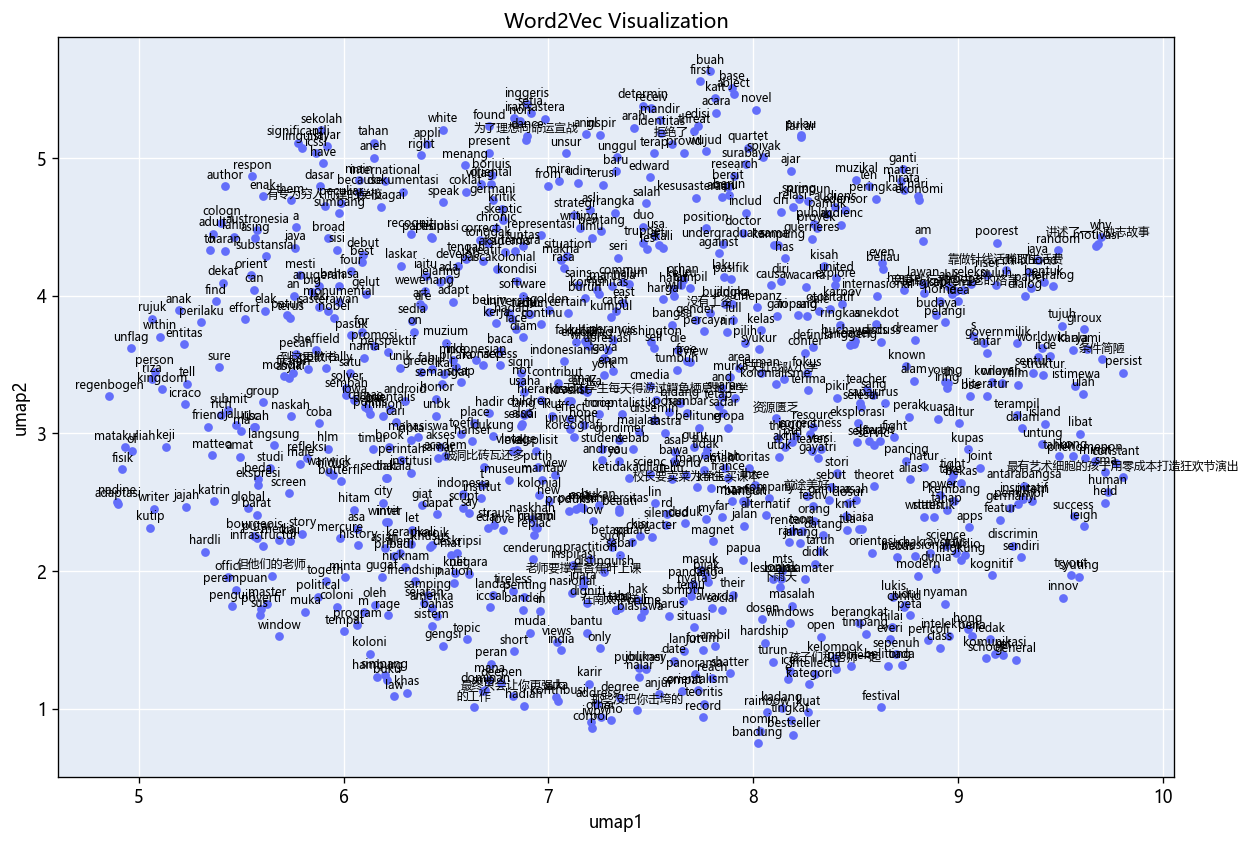

In [ ]:
X_umap = UMAP(random_state=42, n_jobs=1).fit_transform(wv.vectors)
df_visual = pd.DataFrame(X_umap, columns=['umap1', 'umap2'])
df_visual['word'] = wv.index_to_key
fig = px.scatter(df_visual, x='umap1', y='umap2', text='word')
fig.update_traces(textposition='top center')
fig.update_layout(height=800, title_text='Word2Vec Visualization')
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import Image
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
label_font = next((font for font in ['Microsoft YaHei', 'Noto Sans CJK SC',
                                   'Noto Sans CJK JP', 'SimHei', 'DejaVu Sans']
                   if font in available_fonts), 'sans-serif')
with plt.rc_context({'font.family': label_font}):
    png_fig, ax = plt.subplots(figsize=(12, 8))
    ax.set_facecolor('#E5ECF6')
    ax.grid(color='white')
    ax.set_axisbelow(True)
    ax.scatter(df_visual['umap1'], df_visual['umap2'], s=18, color='#636EFA')
    for row in df_visual.itertuples():
        ax.annotate(row.word, (row.umap1, row.umap2), xytext=(0, 3),
                    textcoords='offset points', ha='center', va='bottom', fontsize=7)
    ax.set(xlabel='umap1', ylabel='umap2', title=fig.layout.title.text)
    png_path = RESULT / 'word2vec_umap.png'
    png_fig.savefig(png_path, dpi=120, bbox_inches='tight')
    plt.close(png_fig)
display(Image(filename=str(png_path)))

fig.show(renderer='plotly_mimetype')
df_visual.to_csv(RESULT / 'word2vec_umap.csv', index=False, encoding='utf-8-sig')
fig.write_html(RESULT / 'word2vec_umap.html', include_plotlyjs=True)


### 7. FastText

In [ ]:
model = FastText(sentences, min_count=1, vector_size=100, window=5, min_n=3, max_n=6, sg=1, epochs=10, bucket=20000, workers=1, seed=1)
model.save(str(RESULT / 'fasttext.model'))
model = FastText.load(str(RESULT / 'fasttext.model'))
wv = model.wv
display(wv.index_to_key[:10])
display((wv.vectors.shape, wv.vector_size))
probe = next((word for word in ['pelangi', 'andrea', 'indonesia'] if word in wv.key_to_index), wv.index_to_key[0])
display(wv.similar_by_key(probe, topn=min(10, len(wv)-1)))
X_features = np.array([get_document_vector(doc, model) for doc in sentences])
display(pd.DataFrame(X_features))
np.save(RESULT / 'fasttext_document_vectors.npy', X_features)
np.save(RESULT / 'fasttext_word_vectors.npy', wv.vectors)
pd.DataFrame({'word': wv.index_to_key}).to_csv(
    RESULT / 'fasttext_vocabulary.csv', index=False, encoding='utf-8-sig')


['indonesia',
 'tulis',
 'bahasa',
 'laki',
 'tidak',
 'siswa',
 'suara',
 'budaya',
 'film',
 'barat']

((813, 100), 100)

[('pandang', 0.9998914003372192),
 ('indonesia', 0.9998872876167297),
 ('indonesian', 0.9998856782913208),
 ('orang', 0.9998839497566223),
 ('belitung', 0.9998806715011597),
 ('oriental', 0.9998801350593567),
 ('seleksi', 0.9998800754547119),
 ('institusi', 0.9998798966407776),
 ('orientalistik', 0.9998794794082642),
 ('institusional', 0.9998787045478821)]

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
0,-0.032206,0.024343,0.093696,-0.106700,0.034295,0.069654,0.123060,0.031958,-0.015720,0.039096,...,-0.009347,-0.039631,0.012724,0.024203,0.024445,0.122239,0.031316,-0.138920,0.002546,-0.049922
1,-0.033257,0.025476,0.098304,-0.113437,0.036351,0.073591,0.129041,0.033963,-0.016290,0.041192,...,-0.009670,-0.041780,0.013054,0.025716,0.025381,0.128890,0.033906,-0.146711,0.003076,-0.052397
2,-0.018463,0.014255,0.055063,-0.063030,0.020176,0.041298,0.072323,0.019169,-0.009149,0.023092,...,-0.005426,-0.023427,0.007232,0.014176,0.014378,0.071917,0.019077,-0.081889,0.001501,-0.029397
3,-0.035485,0.026873,0.104156,-0.119238,0.038508,0.077846,0.136192,0.036051,-0.017615,0.043546,...,-0.010241,-0.043840,0.013195,0.026348,0.026955,0.136041,0.035829,-0.154888,0.003150,-0.055710
4,-0.033999,0.025621,0.098730,-0.113062,0.036467,0.073604,0.129087,0.033508,-0.016609,0.041560,...,-0.009617,-0.041360,0.012114,0.026034,0.025841,0.129463,0.033821,-0.147222,0.002103,-0.052769
5,-0.040069,0.030114,0.117469,-0.135616,0.043347,0.088068,0.154136,0.040682,-0.019923,0.049173,...,-0.010983,-0.050064,0.015541,0.030755,0.030176,0.154155,0.040073,-0.175145,0.003356,-0.063078
6,-0.038132,0.029217,0.112528,-0.130697,0.041652,0.084426,0.148620,0.038756,-0.019236,0.046529,...,-0.010615,-0.047857,0.014458,0.029685,0.029481,0.147751,0.038329,-0.168305,0.003021,-0.060090
7,-0.032155,0.024151,0.094431,-0.108917,0.034584,0.070603,0.124314,0.031993,-0.016182,0.040150,...,-0.008947,-0.039812,0.011845,0.024634,0.024640,0.123600,0.032237,-0.140703,0.002753,-0.050739
8,-0.034693,0.026608,0.104595,-0.120235,0.037863,0.078877,0.137884,0.035303,-0.017297,0.044818,...,-0.010584,-0.044162,0.013706,0.027580,0.027593,0.136829,0.035645,-0.155669,0.002278,-0.055251


### FastText Visualization

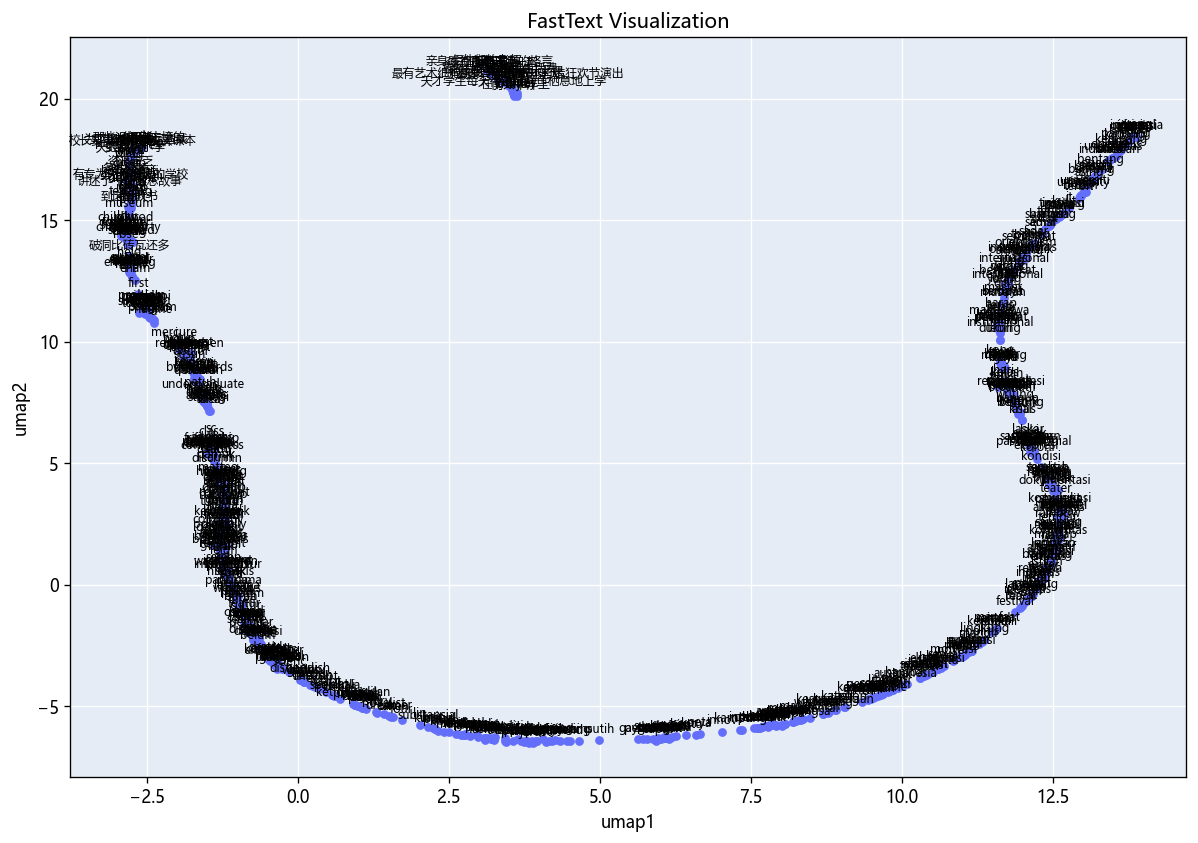

In [ ]:
X_umap = UMAP(random_state=42, n_jobs=1).fit_transform(wv.vectors)
df_visual = pd.DataFrame(X_umap, columns=['umap1', 'umap2'])
df_visual['word'] = wv.index_to_key
fig = px.scatter(df_visual, x='umap1', y='umap2', text='word')
fig.update_traces(textposition='top center')
fig.update_layout(height=800, title_text='FastText Visualization')
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import Image
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
label_font = next((font for font in ['Microsoft YaHei', 'Noto Sans CJK SC',
                                   'Noto Sans CJK JP', 'SimHei', 'DejaVu Sans']
                   if font in available_fonts), 'sans-serif')
with plt.rc_context({'font.family': label_font}):
    png_fig, ax = plt.subplots(figsize=(12, 8))
    ax.set_facecolor('#E5ECF6')
    ax.grid(color='white')
    ax.set_axisbelow(True)
    ax.scatter(df_visual['umap1'], df_visual['umap2'], s=18, color='#636EFA')
    for row in df_visual.itertuples():
        ax.annotate(row.word, (row.umap1, row.umap2), xytext=(0, 3),
                    textcoords='offset points', ha='center', va='bottom', fontsize=7)
    ax.set(xlabel='umap1', ylabel='umap2', title=fig.layout.title.text)
    png_path = RESULT / 'fasttext_umap.png'
    png_fig.savefig(png_path, dpi=120, bbox_inches='tight')
    plt.close(png_fig)
display(Image(filename=str(png_path)))

fig.show(renderer='plotly_mimetype')
df_visual.to_csv(RESULT / 'fasttext_umap.csv', index=False, encoding='utf-8-sig')
fig.write_html(RESULT / 'fasttext_umap.html', include_plotlyjs=True)


### 8. Menyimpan hasil

In [ ]:
parameters = {
    'source': EXERCISE_SOURCE, 'input_mode': input_mode,
    'documents': len(corpus), 'tokenizer': 'nltk.word_tokenize(text.lower())',
    'word2vec': {'sg': 0, 'vector_size': 100, 'window': 5, 'min_count': 1, 'epochs': 5, 'seed': 1, 'workers': 1},
    'fasttext': {'sg': 1, 'vector_size': 100, 'window': 5, 'min_count': 1, 'min_n': 3, 'max_n': 6,
                 'epochs': 10, 'bucket': 20000, 'seed': 1, 'workers': 1},
    'umap': {'random_state': 42, 'n_jobs': 1, 'metric': 'euclidean', 'n_neighbors': 15},
}
(RESULT / 'parameters.json').write_text(json.dumps(parameters, indent=2), encoding='utf-8')
execution = {'status': 'completed', 'source': EXERCISE_SOURCE, 'input_mode': input_mode,
             'documents': len(corpus), 'timestamp_utc': datetime.now(timezone.utc).isoformat(),
             'earlier_scraping_and_preprocessing_rerun': False,
             'package_versions': {p: im.version(p) for p in REQUIRED}}
(RESULT / 'execution_status.json').write_text(json.dumps(execution, indent=2), encoding='utf-8')


530

## Exercise 6

Menerapkan **text similarity** pada hasil **feature engineering** dari Exercise 5 dan menganalisis hasilnya. Teknik yang dipakai: **TF-IDF** dengan **cosine similarity** (data deskripsi buku Google Books API, 9 dokumen).

### 1. Persiapan data

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

if 'RESULT' not in globals():
    RESULT = Path('feature_engineering_result') / 'API'
if 'corpus' not in globals():
    corpus = pd.read_csv(RESULT / 'corpus.csv', keep_default_na=False, encoding='utf-8-sig')
df_pre = corpus['prepro']
labels = corpus['doc_id'].tolist()
print("Jumlah dokumen :", len(df_pre))
display(corpus[['doc_id', 'judul']])

Jumlah dokumen : 9


,doc_id,judul
0,D01,The Rainbow Troops
1,D02,LASKAR PELANGI
2,D03,Rainbow Troops (Mandarin Edition)
3,D04,"Andrea Hirata, Laskar Pelangi - dalam Novel da..."
4,D05,Laskar pelangi
5,D06,Sastra Nasionalisme Pascakolonialitas
6,D07,Explore Bahasa Indonesia Jilid 1 untuk SMP/MTs...
7,D08,Proceedings of the International Joint Confere...
8,D09,Master Kisi-Kisi UN SMA/MA IPS 2019


### 2. Fitur TF-IDF

In [ ]:
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df_pre)
print("Ukuran matriks TF-IDF :", X.shape)

Ukuran matriks TF-IDF : (9, 807)


### 3. Cosine similarity antar dokumen

In [ ]:
similarity = cosine_similarity(X)
df_sim = pd.DataFrame(similarity, index=labels, columns=labels)
display(df_sim.round(3))

,D01,D02,D03,D04,D05,D06,D07,D08,D09
D01,1.000,0.055,0.068,0.028,0.092,0.030,0.005,0.076,0.003
D02,0.055,1.000,0.009,0.100,0.157,0.097,0.013,0.010,0.016
D03,0.068,0.009,1.000,0.000,0.000,0.002,0.000,0.000,0.000
D04,0.028,0.100,0.000,1.000,0.135,0.018,0.027,0.000,0.000
D05,0.092,0.157,0.000,0.135,1.000,0.000,0.000,0.000,0.000
D06,0.030,0.097,0.002,0.018,0.000,1.000,0.071,0.013,0.008
D07,0.005,0.013,0.000,0.027,0.000,0.071,1.000,0.002,0.016
D08,0.076,0.010,0.000,0.000,0.000,0.013,0.002,1.000,0.002
D09,0.003,0.016,0.000,0.000,0.000,0.008,0.016,0.002,1.000


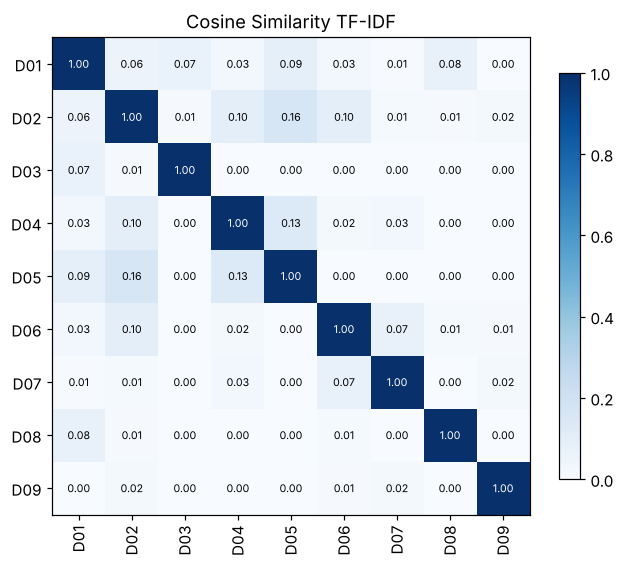

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(similarity, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=90)
ax.set_yticklabels(labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f'{similarity[i, j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if similarity[i, j] > 0.6 else 'black')
ax.set_title('Cosine Similarity TF-IDF')
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

### 4. Pasangan dokumen paling mirip

In [ ]:
iu = np.triu_indices(len(labels), k=1)
pasangan = pd.DataFrame({
    'dokumen_1': [labels[i] for i in iu[0]],
    'dokumen_2': [labels[j] for j in iu[1]],
    'similarity': similarity[iu],
})
display(pasangan.sort_values('similarity', ascending=False).head(10).reset_index(drop=True).round(3))
print("Rata-rata :", round(similarity[iu].mean(), 3))
print("Maksimum  :", round(similarity[iu].max(), 3))
print("Pasangan bernilai 0 :", int((similarity[iu] == 0).sum()), "dari", len(iu[0]))

,dokumen_1,dokumen_2,similarity
0,D02,D05,0.157
1,D04,D05,0.135
2,D02,D04,0.100
3,D02,D06,0.097
4,D01,D05,0.092
5,D01,D08,0.076
6,D06,D07,0.071
7,D01,D03,0.068
8,D01,D02,0.055
9,D01,D06,0.030


Rata-rata : 0.029
Maksimum  : 0.157
Pasangan bernilai 0 : 11 dari 36


### 5. Dokumen terdekat untuk setiap dokumen

In [ ]:
sim_lain = similarity.copy()
np.fill_diagonal(sim_lain, -1)
terdekat = sim_lain.argmax(axis=1)
display(pd.DataFrame({
    'dokumen': labels,
    'terdekat': [labels[i] for i in terdekat],
    'similarity': sim_lain.max(axis=1),
}).round(3))

,dokumen,terdekat,similarity
0,D01,D05,0.092
1,D02,D05,0.157
2,D03,D01,0.068
3,D04,D05,0.135
4,D05,D02,0.157
5,D06,D02,0.097
6,D07,D06,0.071
7,D08,D01,0.076
8,D09,D02,0.016


### 6. Pencarian dokumen berdasarkan query

Mengikuti contoh data arxiv: query diubah ke vektor TF-IDF dengan vectorizer yang sama, lalu dokumen diurutkan berdasarkan cosine similarity. Query ditulis dengan bentuk kata seperti hasil preprocessing (stemming) supaya terbaca oleh vocabulary.

In [ ]:
TopK = 5
query = "andrea hirata laskar pelangi"

query_tfidf = vectorizer.transform([query])
similarities = cosine_similarity(X, query_tfidf)
top_indices = similarities[:, 0].argsort()[::-1][:TopK]

hasil = pd.DataFrame({
    'doc_id': [labels[i] for i in top_indices],
    'judul': [corpus.iloc[i].judul for i in top_indices],
    'similarity': similarities[top_indices, 0],
})
print("Query :", query)
display(hasil.round(4))

Query : andrea hirata laskar pelangi


,doc_id,judul,similarity
0,D05,Laskar pelangi,0.4867
1,D02,LASKAR PELANGI,0.3224
2,D04,"Andrea Hirata, Laskar Pelangi - dalam Novel da...",0.2770
3,D01,The Rainbow Troops,0.0606
4,D09,Master Kisi-Kisi UN SMA/MA IPS 2019,0.0000


In [ ]:
query = "rainbow troop novel"

query_tfidf = vectorizer.transform([query])
similarities = cosine_similarity(X, query_tfidf)
top_indices = similarities[:, 0].argsort()[::-1][:TopK]

hasil = pd.DataFrame({
    'doc_id': [labels[i] for i in top_indices],
    'judul': [corpus.iloc[i].judul for i in top_indices],
    'similarity': similarities[top_indices, 0],
})
print("Query :", query)
display(hasil.round(4))

Query : rainbow troop novel


,doc_id,judul,similarity
0,D01,The Rainbow Troops,0.2314
1,D03,Rainbow Troops (Mandarin Edition),0.1150
2,D02,LASKAR PELANGI,0.0953
3,D04,"Andrea Hirata, Laskar Pelangi - dalam Novel da...",0.0573
4,D09,Master Kisi-Kisi UN SMA/MA IPS 2019,0.0000


### 7. Analisis hasil

**Nilai kemiripan kecil secara umum.** Rata-rata cosine antar pasangan dokumen hanya 0,029 dan yang tertinggi 0,157 (D02–D05). Sebanyak 11 dari 36 pasangan bernilai 0, artinya tidak ada satu pun kata yang sama. Penyebabnya, 9 deskripsi memakai 807 fitur sehingga tiap dokumen hanya memakai sebagian kecil kosakata, panjang dokumennya timpang (D05 hanya 10 kata unik, D06 sampai 360), dan bahasanya campur: Inggris, Indonesia, Melayu, dan Mandarin.

**Dokumen yang paling mirip adalah yang membahas novel Laskar Pelangi.** Lima pasangan teratas adalah D02–D05 (0,157), D04–D05 (0,135), D02–D04 (0,100), D02–D06 (0,097), dan D01–D05 (0,092). Tiga pasangan pertama berbagi kata *andrea*, *hirata*, *laskar*, *pelangi* (D02–D04 ditambah *novel* dan *sutradara*). D05 menjadi dokumen terdekat bagi D01, D02, dan D04, dan D02 sekaligus D05 saling menjadi dokumen terdekat. Ini sesuai isi dokumennya, jadi TF-IDF dan cosine mampu mengelompokkan dokumen yang berbagi kosakata.

**Ada nilai yang tinggi bukan karena topiknya sama.** D02–D06 mendapat 0,097, hampir setara dengan D02–D04, padahal D06 membahas sastra dan nasionalisme. D06 memiliki 360 kata unik sehingga banyak kata kebetulan sama dengan D02 (23 kata, misalnya *bahasa*, *budaya*, *indonesia*, *tulis*). D08 (prosiding konferensi) paling dekat dengan D01 (0,076) hanya karena kata umum seperti *book*, *educ*, *indonesia*, *intern*, dan D09 (kisi-kisi UN) nyaris tidak mirip dengan siapa pun (tertinggi 0,016).

**Buku yang sama dalam bahasa berbeda tidak terbaca mirip.** D01 (Inggris) dan D02 (Indonesia) membahas buku yang sama tetapi nilainya hanya 0,055. Yang cocok hanya nama dan beberapa kata seperti *andrea*, *hirata*, *laskar*, *pelangi*, *rainbow*. TF-IDF tidak tahu bahwa *troop* setara dengan *laskar*. D03 yang berisi teks Mandarin dan Inggris bernilai 0 terhadap D04, D05, D07, D08, dan D09 dan hanya dekat dengan D01 (0,068) karena sama-sama berbahasa Inggris. D06 dan D07 saling terdekat (0,071) karena sama-sama membahas bahasa dan sastra Indonesia.

**Hasil pencarian dengan query.** Untuk query *andrea hirata laskar pelangi*, D05 berada di peringkat 1 (0,487), disusul D02 (0,322) dan D04 (0,277). D01 juga memuat keempat kata itu tetapi hanya 0,061 karena dokumennya panjang (127 kata unik) sehingga bobot tiap kata kecil. Pada query *rainbow troop novel*, D01 di peringkat 1 (0,231), lalu D03 (0,115), D02 (0,095), dan D04 (0,057). Peringkat dengan nilai 0 (misalnya D09) hanya pengisi urutan, bukan dokumen yang relevan.

**Kesimpulan.** Cosine similarity pada TF-IDF cukup baik untuk menemukan dokumen yang berbagi kosakata, terutama kelompok D01, D02, D04, dan D05, dan urutan pencariannya masuk akal. Kelemahannya muncul pada dokumen lintas bahasa, dokumen yang sangat pendek atau sangat panjang, dan kata umum yang kebetulan sama. Hasilnya akan lebih baik bila bahasanya diseragamkan dan jumlah dokumennya lebih banyak.

## Exercise 7 — Text Clustering menggunakan TF-IDF



### 1. Mengambil fitur TF-IDF dari Exercise 5

In [ ]:
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import hashlib
import importlib.metadata as package_metadata
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy import sparse
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from wordcloud import WordCloud
from IPython.display import display, Markdown

In [ ]:
# Snapshot lengkap corpus.csv Exercise 5, untuk menjalankan bagian ini secara mandiri.
# Isinya tetap berupa hasil preprocessing; tidak ada scraping baru.
snapshot_ex7 = [{'doc_id': 'D01', 'id': 'ZPi96HIG76AC', 'judul': 'The Rainbow Troops', 'sumber': 'API', 'source_row': 1, 'prepro': 'andrea hirata indonesian novelist debut novel rainbow troop known laskar pelangi indonesia shatter nation sale record make best sell author indonesia date reach million reader contribut significantli develop modern indonesian literatur rainbow troop set belitong island indonesia tell stori tight knit group student teacher fight educ digniti even face continu hardship fabul rich natur resourc belitong also home chronic poverti educ discrimin amaz stori tell persist young teacher tireless effort fight ten student right educ togeth take reader journey beauti childhood friendship inspir love power educ student magnet person unflag determin sure inspir inspir novel first book rainbow troop quartet sang pemimpi dreamer edensor maryamah karpov three book seri rainbow troop adapt big screen found success not indonesia also worldwid receiv award recognit includ berlin intern film festiv screen panorama golden butterfli award rd intern children young adult film festiv iran rd place audienc award th udin far east intern film signi award hong kong intern film festiv best film bandung film festiv best film indonesian film festiv nomin best film asian film award best film cinepanz award th children film festiv cologn germani mizan bentang novel inspirasi indonesia'}, {'doc_id': 'D02', 'id': '8MtoEQAAQBAJ', 'judul': 'LASKAR PELANGI', 'sumber': 'API', 'source_row': 2, 'prepro': 'andrea hirata tang anugerah sastera peringkat antarabangsa beliau tang new york book festival terusi naskhah the rainbow troops laskar pelangi edisi amerika terbit farrar straus giroux new york kategori general fiction beliau juara buchawards germany terusi naskhah die regenbogen truppe iaitu laskar pelangi edisi jerman terbit hanser lin andrea tang seleksi short story majalah sastera muka amerika washington square review new york university edisi winter spring karya pena judul my sus sebar menang hadiah nobel kesusasteraan orhan pamuk nadine gordimer esei hirata judul view from my window pilih buku windows on the world writers views matteo pericoli penguin new york andrea biasiswa didik sastera international writing program iwp university of iowa usa international bestseller laskar pelangi the rainbow troops terbit versi bahasa asing edar buah negara rujuk sekolah institusi negara studi didik sastera budaya indonesia the rainbow troops pilih karya sastera kategori vintage terbit random house lonjak sasterawan timur novel gari novel adaptasi negara filem teater muzikal audio book koreografi washington city dance company usa sutradara inggeris mike leigh andrea hirata anugerah doctor honor causa bidang sastera university of warwick united kingdom beliau terima harga budaya perintah perancis karya les guerrieres de laskar pelangi laskar pelangi edisi perancis terbit mercure de france andrea jaya raih master of science m sc bidang teori ekonomi sheffield hallam university united kingdom terima biasiswa andrea nama tulis kreatif pelbagai universiti negara promosi minat baca tulis puluh muzium sastera sendiri satu indonesia iaitu museum andrea hirata kampung lahir belitong'}, {'doc_id': 'D03', 'id': 'Q5OrAgAAQBAJ', 'judul': 'Rainbow Troops (Mandarin Edition)', 'sumber': 'API', 'source_row': 3, 'prepro': '天虹战队小学 ikal student poorest villag school constant threat closur ikal friend group nicknam rainbow troop face threat everi angl skeptic govern offici greedi corpor hardli distinguish coloni replac deepen poverti crumbl infrastructur low self confid student also hope 天虹战队小学 讲述了一个励志故事 在南太平洋上 有专为穷人而建的学校 条件简陋 资源匮乏 破洞比砖瓦还多 下雨天 老师要撑着香蕉叶上课 校长要卖菜为学生买课本 天才学生每天得游过鳄鱼栖息地上学 最有艺术细胞的孩子用零成本打造狂欢节演出 但他们的老师 拒绝了 前途美好 的工作 到这里教书 没有工资 靠做针线活赚取生活费 孩子们和老师一起 为了理想向命运宣战 亲身践行那句古老的格言 那些没把你击垮的 最终只会让你更强大'}, {'doc_id': 'D04', 'id': '8JTTDwAAQBAJ', 'judul': 'Andrea Hirata, Laskar Pelangi - dalam Novel dan Film', 'sumber': 'API', 'source_row': 4, 'prepro': 'novel andrea hirata ledak sutradara riri riza coba lukis laskar pelangi layar perak enam kali mondar mandir belitung ada riset tahun cari main asli duduk belitung duo mira lesmana riri riza tampil kisah anak syuting laskar pelangi belitung orang guru penuh semangat inspiratif sentuh'}, {'doc_id': 'D05', 'id': 'jUvvwAEACAAJ', 'judul': 'Laskar pelangi', 'sumber': 'API', 'source_row': 5, 'prepro': 'phenomenon laskar pelangi tetralog andrea hirata indonesian writer effect reader'}, {'doc_id': 'D06', 'id': 'KH0oBQAAQBAJ', 'judul': 'Sastra Nasionalisme Pascakolonialitas', 'sumber': 'API', 'source_row': 6, 'prepro': 'antar katrin bandel salah unsur penting tulis esei posisi posisi makna dapat arti ekspresi pandang nilai masalah kembang jangka tujuh dokumentasi kumpul esei usaha posisi eksplisit kait peta relasi kuasa global posisi dalam perempuan kulit putih eropa tulis bahasa indonesia mana diri identitas perempuan kulit putih eropa kait giat tulis tulis gelut berangkat anekdot cerita pikir pascakolonial india gayatri chakravorty spivak dialog putar representasi i will have in an undergraduate class let s say a young white male student politically correct who will say i am only a bourgeois white male i can t speak in that situation it s peculiar because i am in the position of power and their teacher and on the other hand i am not a bourgeois white male i say to them why not develop a certain degree of rage against the history that has written such an abject script for you that you are silenced gayatri chakravorty spivak hlm kelas matakuliah s ampu mahasiswa laki laki muda kulit putih sikap politically correct laki laki borjuis kulit putih tidak bicara situasi situasi unik posisi kuasa dosen sisi bukan laki laki borjuis kulit putih tidak coba tingkat tumbuh murka sejarah tulis naskah keji tidak bicara mahasiswa laki laki borjuis kulit putih tidak bicara mahasiswa berangkat sadar identitas cenderung tempat posisi untung laki laki borjuis kulit putih hak bicara arti sempat suara pandang publik partisipasi ambil bijak nasional lokal global manusia perempuan kelas buruh orang kulit coklat hitam bicara tidak sempat suara political correctness anekdot dasar sadar ketidakadilan kondisi laki laki borjuis kulit putih bicara suara otoritatif sediakala bidang bidang akademis situasi ubah substansial suara suara hadir tidak jarang gugat perspektif teoritis kembang kaji pascakolonial kaji gender kaji budaya berangkat sadar kembang mana posisi laki laki borjuis kulit putih posisi otoritatif cenderung tiada perspektif ada pilih sedia mahasiswa anekdot spivak tidak alternatif satu pilih diam bukan laki laki orang eropa kulit putih asal kelas tengah sapa anekdot cerita spivak sesuai spivak tidak jarang script naskah sedia script enak setia bidang studi pilih kuliah dunia barat indonesianis peran budaya indonesia orang bangsa komunitas akademis internasional alias komunitas akademis bahasa inggris duduk posisi otoritatif ahli indonesia wewenang khusus bicara indonesia forum forum catat orang indonesia kerapkali milik akses suara forum mana datang script karya monumental orientalism kerapkali tonggak kaji pascakolonial edward said deskripsi betapa tradisi pikir barat tumbuh wacana khusus orient timur wacana oriental timur ajar entitas konon milik ciri khas beda substansial barat wacana hadir suara otoritatif definisi kuasa timur otoritas suara langsung kait kuasa wacana oriental kembang sama kolonialisme tahu timur jajah fisik topang dunia akademis oriental ambil bentuk institusi institusi khusus dukung studi budaya oriental struktur kerapkali bekas orientasi ilmu alami ubah kuliah universitas hamburg jerman fakultas ajar budaya indonesia nama orientalistik jurus ambil jurus bahasa budaya austronesia bahasa indonesia ajar rumpun bahasa austronesia salah jurus tua universitas jurus institut kolonial jerman milik koloni wilayah pulau pasifik papua struktur struktur langgeng relasi kuasa global timpang universitas negara negara barat ajar budaya budaya dunia tahu publikasi bahasa inggris bahasa eropa media media akademis pandang gengsi percaya manusia manusia budaya ajar kerapkali ajar bahasa budaya barat bukan rangka oleh suara otoritatif manusia barat bicara timur akses dunia barat rasa nyata tahu gaya hidup barat dominan global tidak jarang budaya ajar tahu barat tulis teliti asing orientalis manusia eropa didik orientalis tidak elak wacana institusional struktur struktur orientalis hierarkis tahan manusia manusia struktur belum sepenuh patuh teliti barat bidang studi asia afrika sebut salah istilah ganti istilah oriental almamater universitas hamburg sikap kritis struktur struktur ekspresi kritik tulis tulis samping usaha libat suara suara non barat produksi tahu alam pribadi struktur timpang rasa samar samar kuliah tidak milik sadar politis kuat tidak sempat ajar teori pascakolonial teori teori bantu semangat kritis pandang dunia alami tahap asa nyaman motivasi pasuk dunia akademis harap produksi tulis tulis bahasa jerman inggris indonesia tulis kerja hambar asyik jalan hidup bawa tetap indonesia sebab kondisi hidup aktif tulis publikasi bukan bahasa jerman inggris bahasa indonesia laku bukan sebab semangat heroik lawan struktur kuasa wacana akademis ikut naluri asyik karya tulis indonesia bahasa indonesia sapa audiens orang orang taruh minat sastra indonesia respon apresiasi oleh rasa betapa kontribusi manfaat nyata baca fokus tulis bahasa indonesia lanjut kembang kadang kadang bersit niat tulis bahasa inggris jerman landas harus cemas tidak refleksi samar samar aneh keliru jalan tulis karir akademis salah jalur bukan kerja laku indonesianis minta sumbang tulis bahasa indonesia bicara acara acara bahasa indonesia terus debat kembang dunia sastra indonesia pancing suara rencana tulis bahasa jerman inggris jarang wujud asyik tulis bahasa indonesia iring fokus tulis bahasa indonesia mantap pilih sempat duduk posisi unik peta relasi kuasa global gambar jalan karir salah jalur ubah makna istimewa syukur rencana sadar simpang script sedia tidak sepenuh elak wacana oriental tidak institusional jalur beda kumpul esei dokumentasi jalan tulis tujuh bawa sadar kritis relasi kuasa global bentuk dunia intelektual karya anekdot kutip spivak anjur murka script keji sedia manusia turun jajah mesti hadap bentuk ketidakadilan sebab ulah bangsa bangsa murka coba eksplisit kembang ekspresi esei esei'}, {'doc_id': 'D07', 'id': 'VXtJEAAAQBAJ', 'judul': 'Explore Bahasa Indonesia Jilid 1 untuk SMP/MTs Kelas VII', 'sumber': 'API', 'source_row': 7, 'prepro': 'buku explore bahasa indonesia smp mts buku kembang dekat sains suka siswa milik unggul materi giat buku susun konsep m amat coba nalar komunikasi bentuk jejaring siswa libat aktif giat ajar tuntun siswa bentuk bangun tahu giat proyek kelompok cipta komunikasi arah siswa siswa siswa guru orang tua siswa orang orang siswa asah sikap peduli lingkung siswa harap terap tahu terampil sikap perilaku hari character building buku biasa siswa kreatif bebas eksplorasi tahu oleh siswa biasa temu alternatif selesai hadap siswa harap pecah problem solver'}, {'doc_id': 'D08', 'id': 'mX60EAAAQBAJ', 'judul': 'Proceedings of the International Joint Conference on Arts and Humanities 2022 (IJCAH 2022)', 'sumber': 'API', 'source_row': 8, 'prepro': 'open access book joint confer featur four intern confer intern confer educ innov icei intern confer cultur studi appli linguist iccsal intern confer research academ commun servic icraco intern confer social scienc law icssl encourag dissemin idea art human provid forum intellectu world discuss present research find research area confer held surabaya east java indonesia septemb septemb invit academ research practition submit research base paper theoret paper address topic within broad area art human'}, {'doc_id': 'D09', 'id': 'iWlvDwAAQBAJ', 'judul': 'Master Kisi-Kisi UN SMA/MA IPS 2019', 'sumber': 'API', 'source_row': 9, 'prepro': 'full strategi kupas tuntas kisi kisi baru full ringkas materi sesuai kisi kisi baru full kumpul lengkap bahas lengkap kisi kisi baru statistik un lengkap level kognitif sesuai kisi kisi baru free tryout online sistem unbk free apps android unbk sma ma utbk sbmptn toefl cmedia free software unbk sma ma free software utbk sbmptn free software toefl free e book toefl masuk ptn bse ajar buku sembah terbit cmedia'}]

In [ ]:
calon_folder_ex7 = []
if 'RESULT' in globals():
    calon_folder_ex7.append(Path(RESULT))
calon_folder_ex7.append(Path.cwd() / 'feature_engineering_result' / 'API')
berkas_ex7 = ['corpus.csv', 'tfidf_features.npz', 'tfidf_vectorizer.joblib']
folder_fe_ex7 = next((p for p in calon_folder_ex7
                      if all((p / name).is_file() for name in berkas_ex7)), None)
if folder_fe_ex7 is not None:
    corpus_ex7 = pd.read_csv(folder_fe_ex7 / 'corpus.csv', keep_default_na=False,
                             encoding='utf-8-sig')
    X_sparse_ex7 = sparse.load_npz(folder_fe_ex7 / 'tfidf_features.npz').tocsr()
    vectorizer_ex7 = joblib.load(folder_fe_ex7 / 'tfidf_vectorizer.joblib')
    input_ex7 = 'File fitur TF-IDF Exercise 5'
else:
    corpus_ex7 = None
    for nama_variabel_ex7 in ['corpus', 'corpus_ex6']:
        nilai_ex7 = globals().get(nama_variabel_ex7)
        if isinstance(nilai_ex7, pd.DataFrame) and {'doc_id', 'judul', 'prepro'}.issubset(nilai_ex7.columns):
            corpus_ex7 = nilai_ex7.copy(deep=True)
            input_ex7 = 'Corpus di memori; TF-IDF dihitung ulang'
            break
    if corpus_ex7 is None:
        corpus_ex7 = pd.DataFrame(snapshot_ex7)
        input_ex7 = 'Snapshot Exercise 5 bawaan; TF-IDF dihitung ulang'
    vectorizer_ex7 = TfidfVectorizer()
    X_sparse_ex7 = vectorizer_ex7.fit_transform(corpus_ex7['prepro']).tocsr()

corpus_ex7 = corpus_ex7.reset_index(drop=True)
assert len(corpus_ex7) >= 3, 'Evaluasi silhouette memerlukan minimal tiga dokumen.'
assert corpus_ex7['doc_id'].is_unique
assert corpus_ex7['prepro'].fillna('').str.strip().ne('').all()
assert isinstance(vectorizer_ex7, TfidfVectorizer)
cek_ex7 = vectorizer_ex7.transform(corpus_ex7['prepro'])
assert cek_ex7.shape == X_sparse_ex7.shape
delta_ex7 = (cek_ex7 - X_sparse_ex7).tocsr()
assert not delta_ex7.nnz or np.max(np.abs(delta_ex7.data)) < 1e-10
assert np.all(X_sparse_ex7.getnnz(axis=1) > 0)

# Korpus snapshot kecil (9 x 807); Ward memerlukan matriks dense.
X_cluster_ex7 = X_sparse_ex7.toarray()
assert X_cluster_ex7.shape[0] == len(corpus_ex7)
assert np.isfinite(X_cluster_ex7).all()
assert np.allclose(np.linalg.norm(X_cluster_ex7, axis=1), 1.0)
fitur_ex7 = vectorizer_ex7.get_feature_names_out()
doc_ids_ex7 = corpus_ex7['doc_id'].tolist()
max_k_ex7 = min(6, len(corpus_ex7) - 1, len(np.unique(X_cluster_ex7, axis=0)))
assert max_k_ex7 >= 2, 'Tidak cukup vektor dokumen berbeda untuk clustering.'
HASIL_EX7 = Path.cwd() / 'text_clustering_result' / 'API_TFIDF'
HASIL_EX7.mkdir(parents=True, exist_ok=True)
print('Input:', input_ex7)
print('Matriks TF-IDF:', X_cluster_ex7.shape)
display(corpus_ex7[['doc_id', 'judul', 'source_row']])

Input: File fitur TF-IDF Exercise 5
Matriks TF-IDF: (9, 807)


,doc_id,judul,source_row
0,D01,The Rainbow Troops,1
1,D02,LASKAR PELANGI,2
2,D03,Rainbow Troops (Mandarin Edition),3
3,D04,"Andrea Hirata, Laskar Pelangi - dalam Novel da...",4
4,D05,Laskar pelangi,5
5,D06,Sastra Nasionalisme Pascakolonialitas,6
6,D07,Explore Bahasa Indonesia Jilid 1 untuk SMP/MTs...,7
7,D08,Proceedings of the International Joint Confere...,8
8,D09,Master Kisi-Kisi UN SMA/MA IPS 2019,9


### 2. Memilih jumlah cluster dengan elbow dan silhouette


In [ ]:
model_kmeans_ex7, model_ward_ex7 = {}, {}
baris_elbow_ex7, baris_evaluasi_ex7 = [], []
for k in range(1, max_k_ex7 + 1):
    km = KMeans(n_clusters=k, random_state=10, n_init=20)
    label_km = km.fit_predict(X_cluster_ex7)
    model_kmeans_ex7[k] = km
    baris_elbow_ex7.append({'k': k, 'inertia': float(km.inertia_)})
    if k < 2:
        continue
    ward = AgglomerativeClustering(n_clusters=k, linkage='ward', metric='euclidean')
    label_ward = ward.fit_predict(X_cluster_ex7)
    model_ward_ex7[k] = ward
    for metode, labels in [('KMeans', label_km), ('Ward', label_ward)]:
        ukuran = pd.Series(labels).value_counts()
        baris_evaluasi_ex7.append({
            'metode': metode, 'k': k,
            'silhouette_euclidean': float(silhouette_score(X_cluster_ex7, labels, metric='euclidean')),
            'jumlah_singleton': int((ukuran == 1).sum()),
            'ukuran_cluster': ', '.join(map(str, sorted(ukuran.tolist(), reverse=True))),
        })
elbow_ex7 = pd.DataFrame(baris_elbow_ex7)
evaluasi_k_ex7 = pd.DataFrame(baris_evaluasi_ex7)
pilihan_ex7 = evaluasi_k_ex7.sort_values(
    ['metode', 'silhouette_euclidean', 'k'], ascending=[True, False, True]
).groupby('metode', sort=False).head(1).reset_index(drop=True)
k_kmeans_ex7 = int(pilihan_ex7.loc[pilihan_ex7['metode'] == 'KMeans', 'k'].iloc[0])
k_ward_ex7 = int(pilihan_ex7.loc[pilihan_ex7['metode'] == 'Ward', 'k'].iloc[0])
display(evaluasi_k_ex7.round(6))
print('Pilihan k per metode:')
display(pilihan_ex7.round(6))

Pilihan k per metode:


,metode,k,silhouette_euclidean,jumlah_singleton,ukuran_cluster
0,KMeans,2,0.015482,0,"5, 4"
1,Ward,2,0.019030,0,"6, 3"
2,KMeans,3,0.024315,0,"3, 3, 3"
3,Ward,3,0.024315,0,"3, 3, 3"
4,KMeans,4,0.025982,1,"3, 3, 2, 1"
5,Ward,4,0.025982,1,"3, 3, 2, 1"
6,KMeans,5,0.025233,2,"3, 2, 2, 1, 1"
7,Ward,5,0.025233,2,"3, 2, 2, 1, 1"
8,KMeans,6,0.017265,4,"3, 2, 1, 1, 1, 1"
9,Ward,6,0.017265,4,"3, 2, 1, 1, 1, 1"


,metode,k,silhouette_euclidean,jumlah_singleton,ukuran_cluster
0,KMeans,4,0.025982,1,"3, 3, 2, 1"
1,Ward,4,0.025982,1,"3, 3, 2, 1"


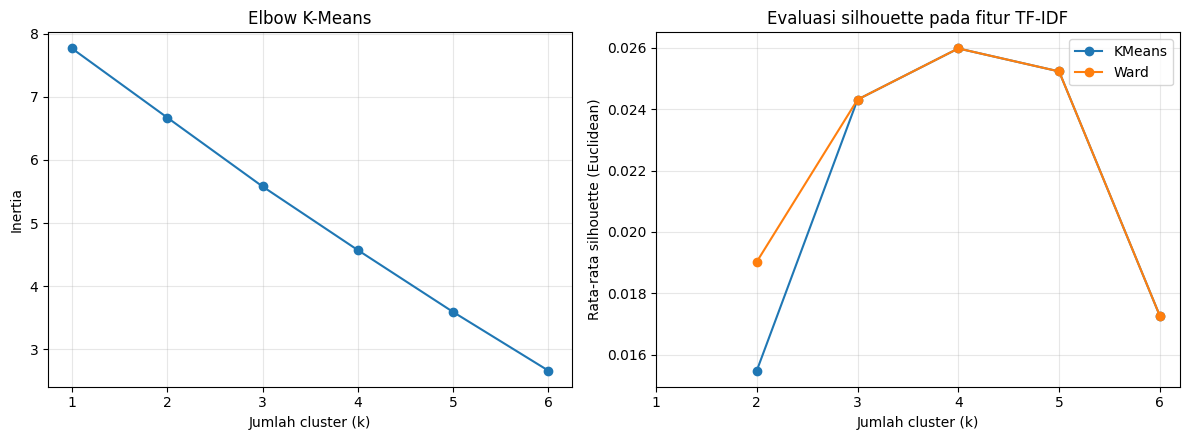

In [ ]:
fig_evaluasi_ex7, axes_ex7 = plt.subplots(1, 2, figsize=(12, 4.5))
axes_ex7[0].plot(elbow_ex7['k'], elbow_ex7['inertia'], marker='o')
axes_ex7[0].set(title='Elbow K-Means', xlabel='Jumlah cluster (k)', ylabel='Inertia')
for metode, kelompok in evaluasi_k_ex7.groupby('metode', sort=False):
    axes_ex7[1].plot(kelompok['k'], kelompok['silhouette_euclidean'], marker='o', label=metode)
axes_ex7[1].set(title='Evaluasi silhouette pada fitur TF-IDF', xlabel='Jumlah cluster (k)',
                 ylabel='Rata-rata silhouette (Euclidean)')
axes_ex7[1].legend()
for ax in axes_ex7:
    ax.set_xticks(range(1, max_k_ex7 + 1))
    ax.grid(alpha=0.3)
fig_evaluasi_ex7.tight_layout()
plt.show()

### 3. Hasil K-Means dan Hierarchical/Ward


In [ ]:
kmeans_ex7 = model_kmeans_ex7[k_kmeans_ex7]
ward_ex7 = model_ward_ex7[k_ward_ex7]

def nomor_cluster_ex7(raw_labels):
    urutan = sorted(np.unique(raw_labels), key=lambda label: np.flatnonzero(raw_labels == label)[0])
    peta = {int(label): i + 1 for i, label in enumerate(urutan)}
    return np.array([peta[int(label)] for label in raw_labels]), peta

label_kmeans_ex7, peta_kmeans_ex7 = nomor_cluster_ex7(kmeans_ex7.labels_)
label_ward_ex7, peta_ward_ex7 = nomor_cluster_ex7(ward_ex7.labels_)
hasil_cluster_ex7 = corpus_ex7.copy(deep=True)
hasil_cluster_ex7['kmeans_label_raw'] = kmeans_ex7.labels_
hasil_cluster_ex7['ward_label_raw'] = ward_ex7.labels_
hasil_cluster_ex7['kmeans_cluster'] = label_kmeans_ex7
hasil_cluster_ex7['ward_cluster'] = label_ward_ex7
hasil_cluster_ex7['silhouette_kmeans'] = silhouette_samples(X_cluster_ex7, label_kmeans_ex7, metric='euclidean')
hasil_cluster_ex7['silhouette_ward'] = silhouette_samples(X_cluster_ex7, label_ward_ex7, metric='euclidean')
display(hasil_cluster_ex7[['doc_id', 'judul', 'kmeans_cluster', 'ward_cluster',
                          'silhouette_kmeans', 'silhouette_ward']].round(6))

ari_ex7 = float(adjusted_rand_score(label_kmeans_ex7, label_ward_ex7))
perbandingan_ex7 = pilihan_ex7.copy()
perbandingan_ex7['fitur'] = 'TF-IDF'
perbandingan_ex7['jumlah_dokumen'] = len(corpus_ex7)
print('Perbandingan metode pada k yang dipilih:')
display(perbandingan_ex7.round(6))
print('Adjusted Rand Index antarhasil kedua metode:', round(ari_ex7, 6))

silhouette_dokumen_ex7 = pd.concat([
    pd.DataFrame({'metode': metode, 'doc_id': doc_ids_ex7, 'cluster': labels,
                  'silhouette': silhouette_samples(X_cluster_ex7, labels, metric='euclidean')})
    for metode, labels in [('KMeans', label_kmeans_ex7), ('Ward', label_ward_ex7)]
], ignore_index=True)

Perbandingan metode pada k yang dipilih:
Adjusted Rand Index antarhasil kedua metode: 1.0


,doc_id,judul,kmeans_cluster,ward_cluster,silhouette_kmeans,silhouette_ward
0,D01,The Rainbow Troops,1,1,0.007070,0.007070
1,D02,LASKAR PELANGI,2,2,0.039635,0.039635
2,D03,Rainbow Troops (Mandarin Edition),1,1,0.015704,0.015704
3,D04,"Andrea Hirata, Laskar Pelangi - dalam Novel da...",2,2,0.049778,0.049778
4,D05,Laskar pelangi,2,2,0.061067,0.061067
5,D06,Sastra Nasionalisme Pascakolonialitas,3,3,0.016664,0.016664
6,D07,Explore Bahasa Indonesia Jilid 1 untuk SMP/MTs...,3,3,0.028303,0.028303
7,D08,Proceedings of the International Joint Confere...,1,1,0.015621,0.015621
8,D09,Master Kisi-Kisi UN SMA/MA IPS 2019,4,4,0.000000,0.000000


,metode,k,silhouette_euclidean,jumlah_singleton,ukuran_cluster,fitur,jumlah_dokumen
0,KMeans,4,0.025982,1,"3, 3, 2, 1",TF-IDF,9
1,Ward,4,0.025982,1,"3, 3, 2, 1",TF-IDF,9


### 4. Dendrogram Hierarchical/Ward

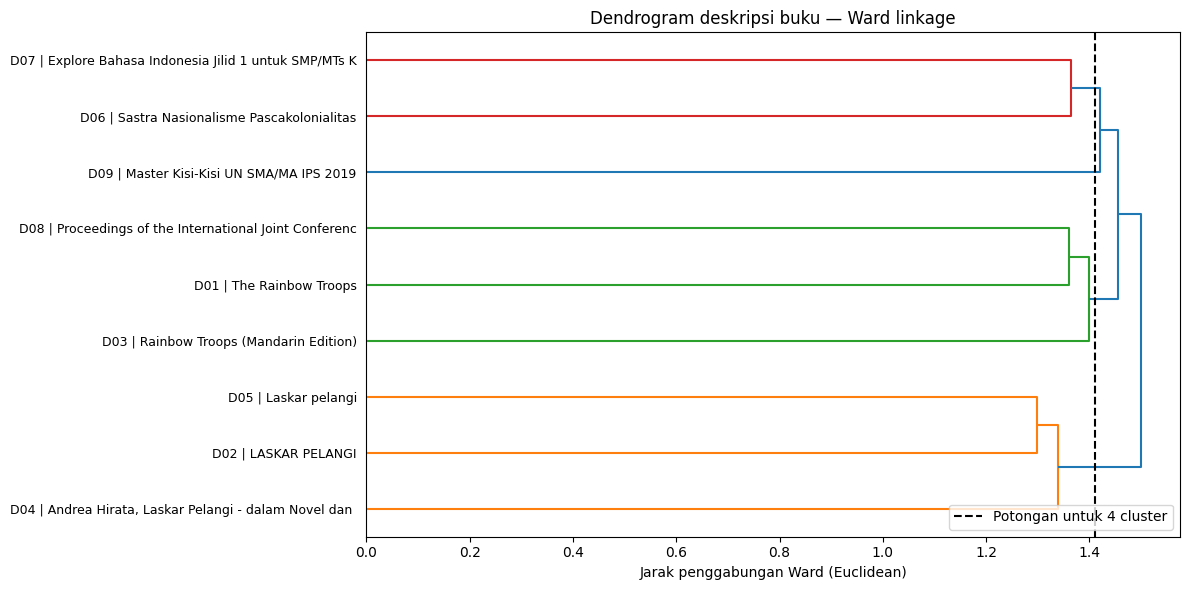

In [ ]:
linkage_ex7 = linkage(X_cluster_ex7, method='ward', metric='euclidean')
fig_dendrogram_ex7, ax_dendrogram_ex7 = plt.subplots(figsize=(12, 6))
label_dendrogram_ex7 = [f"{row.doc_id} | {row.judul[:48]}" for row in corpus_ex7.itertuples()]
jumlah_merge_ex7 = len(corpus_ex7) - k_ward_ex7
batas_potong_ex7 = float((linkage_ex7[jumlah_merge_ex7 - 1, 2] + linkage_ex7[jumlah_merge_ex7, 2]) / 2)
dendrogram(linkage_ex7, labels=label_dendrogram_ex7, orientation='right',
           leaf_font_size=9, color_threshold=batas_potong_ex7, ax=ax_dendrogram_ex7)
ax_dendrogram_ex7.axvline(batas_potong_ex7, color='black', linestyle='--',
                         label=f'Potongan untuk {k_ward_ex7} cluster')
ax_dendrogram_ex7.set_title('Dendrogram deskripsi buku — Ward linkage')
ax_dendrogram_ex7.set_xlabel('Jarak penggabungan Ward (Euclidean)')
ax_dendrogram_ex7.legend(loc='lower right')
fig_dendrogram_ex7.tight_layout()
plt.show()

### 5. Anggota, kata dominan, dan word cloud setiap cluster



,metode,cluster,jumlah_dokumen,doc_ids,kata_dominan
0,KMeans,1,3,"D01, D03, D08","film, confer, intern, research, student, award..."
1,KMeans,2,3,"D02, D04, D05","laskar, pelangi, andrea, hirata, belitung, eff..."
2,KMeans,3,2,"D06, D07","siswa, tulis, bahasa, laki, tidak, tahu, indon..."
3,KMeans,4,1,D09,"kisi, free, baru, full, lengkap, software, toe..."
4,Ward,1,3,"D01, D03, D08","film, confer, intern, research, student, award..."
5,Ward,2,3,"D02, D04, D05","laskar, pelangi, andrea, hirata, belitung, eff..."
6,Ward,3,2,"D06, D07","siswa, tulis, bahasa, laki, tidak, tahu, indon..."
7,Ward,4,1,D09,"kisi, free, baru, full, lengkap, software, toe..."


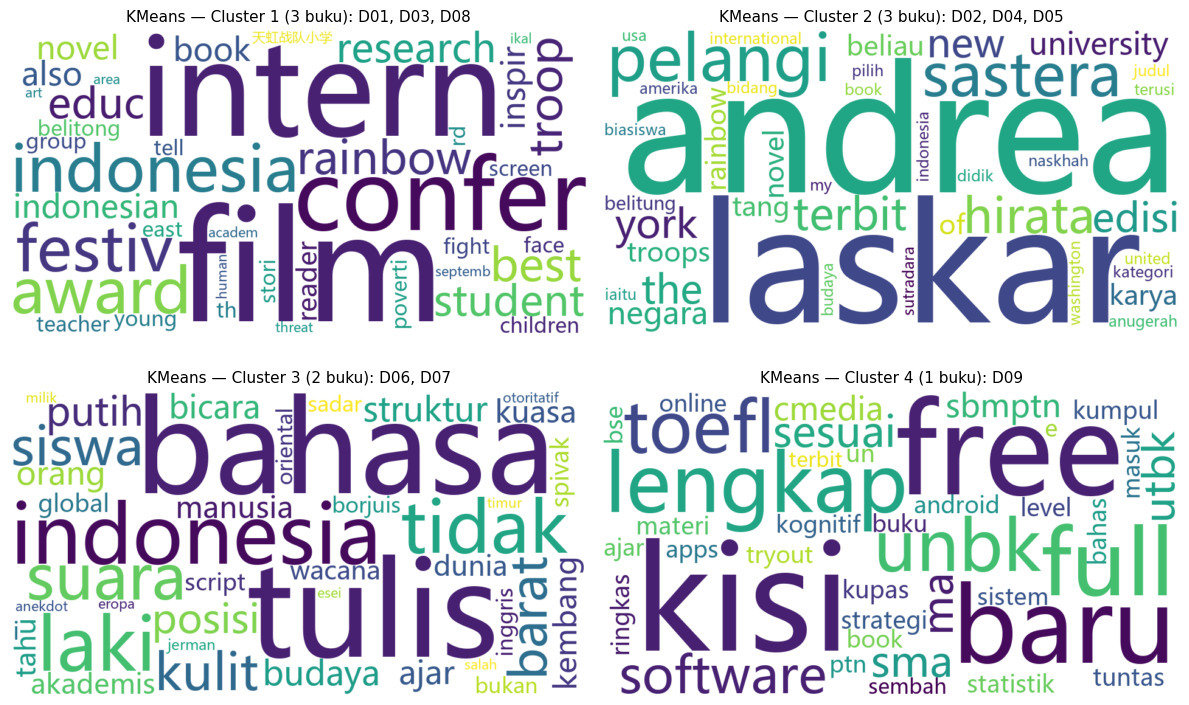

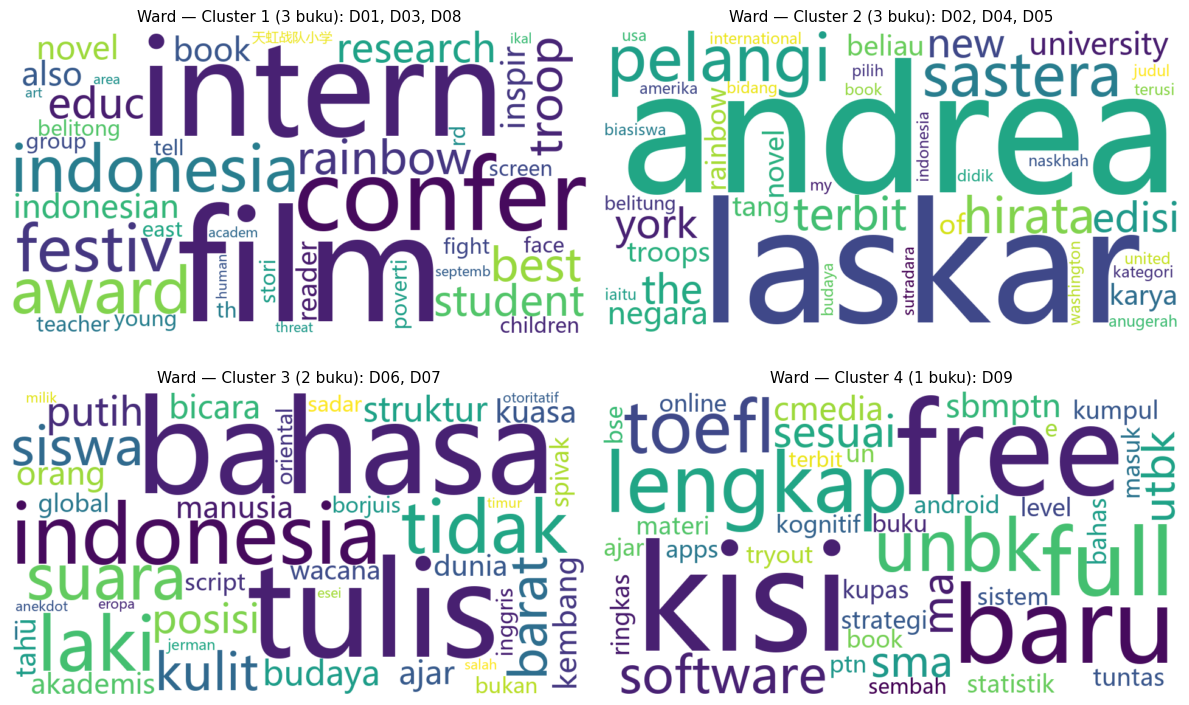

In [ ]:
baris_ringkasan_ex7, baris_kata_ex7 = [], []
for metode, labels in [('KMeans', label_kmeans_ex7), ('Ward', label_ward_ex7)]:
    for cluster_id in sorted(np.unique(labels)):
        indeks = np.flatnonzero(labels == cluster_id)
        bobot = X_cluster_ex7[indeks].mean(axis=0)
        urutan = sorted(np.flatnonzero(bobot > 0), key=lambda j: (-bobot[j], fitur_ex7[j]))[:10]
        baris_ringkasan_ex7.append({
            'metode': metode, 'cluster': int(cluster_id), 'jumlah_dokumen': len(indeks),
            'doc_ids': ', '.join(corpus_ex7.iloc[indeks]['doc_id']),
            'judul_buku': ' | '.join(corpus_ex7.iloc[indeks]['judul']),
            'kata_dominan': ', '.join(fitur_ex7[urutan]),
        })
        for rank, j in enumerate(urutan, start=1):
            baris_kata_ex7.append({'metode': metode, 'cluster': int(cluster_id),
                                  'peringkat': rank, 'kata': fitur_ex7[j],
                                  'rata_rata_tfidf': float(bobot[j])})
ringkasan_cluster_ex7 = pd.DataFrame(baris_ringkasan_ex7)
kata_cluster_ex7 = pd.DataFrame(baris_kata_ex7)
display(ringkasan_cluster_ex7[['metode', 'cluster', 'jumlah_dokumen', 'doc_ids', 'kata_dominan']])

fig_wordcloud_ex7 = {}
calon_font_ex7 = [
    Path('/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc'),
    Path('/usr/share/fonts/truetype/wqy/wqy-zenhei.ttc'),
    Path('C:/Windows/Fonts/msyh.ttc'),
    Path('C:/Windows/Fonts/NotoSansSC-VariableFont_wght.ttf'),
]
font_ex7 = next((str(p) for p in calon_font_ex7 if p.is_file()), None)
for metode, labels in [('KMeans', label_kmeans_ex7), ('Ward', label_ward_ex7)]:
    cluster_ids = sorted(np.unique(labels))
    ncols = 2
    nrows = int(np.ceil(len(cluster_ids) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.8 * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, cluster_id in zip(axes.ravel(), cluster_ids):
        anggota = corpus_ex7.loc[labels == cluster_id]
        counts = Counter(token for teks in anggota['prepro'] for token in teks.split())
        cloud = WordCloud(width=950, height=500, background_color='white',
                          max_words=40, collocations=False, random_state=42,
                          font_path=font_ex7, stopwords=set()).generate_from_frequencies(counts)
        ax.imshow(cloud, interpolation='bilinear')
        ax.set_title(f"{metode} — Cluster {cluster_id} ({len(anggota)} buku): "
                     + ', '.join(anggota['doc_id']), fontsize=11)
    fig.tight_layout()
    fig_wordcloud_ex7[metode] = fig
    plt.show()

### 6. Analisis hasil clustering

In [ ]:
skor_kmeans_ex7 = float(perbandingan_ex7.loc[perbandingan_ex7['metode'] == 'KMeans',
                                           'silhouette_euclidean'].iloc[0])
skor_ward_ex7 = float(perbandingan_ex7.loc[perbandingan_ex7['metode'] == 'Ward',
                                         'silhouette_euclidean'].iloc[0])
daftar_cluster_ex7 = '\n'.join(
    f"- **{row.metode}, cluster {row.cluster}:** {row.doc_ids} "
    f"({row.jumlah_dokumen} buku). Kata dominan: {row.kata_dominan}."
    for row in ringkasan_cluster_ex7.itertuples()
)
display(Markdown(f"""
**Pemilihan jumlah cluster.** Dari kandidat k=2 sampai {max_k_ex7}, nilai silhouette
tertinggi K-Means diperoleh pada **k={k_kmeans_ex7}**, dengan skor
**{skor_kmeans_ex7:.6f}**. Ward memilih **k={k_ward_ex7}**, dengan skor
**{skor_ward_ex7:.6f}**. Grafik elbow dan tabel kandidat membantu memeriksa apakah
penambahan cluster memberikan perubahan yang berarti.

**Anggota kelompok.**

{daftar_cluster_ex7}

**Kesepakatan metode.** Adjusted Rand Index antara kedua hasil adalah
**{ari_ex7:.6f}**. Nilai 1 berarti kedua metode menghasilkan pembagian anggota
yang sama, walaupun nomor label mentahnya dapat berbeda. Ini mengukur kesepakatan
antarmetode, bukan akurasi terhadap kategori buku yang benar.
"""))


**Pemilihan jumlah cluster.** Dari kandidat k=2 sampai 6, nilai silhouette
tertinggi K-Means diperoleh pada **k=4**, dengan skor
**0.025982**. Ward memilih **k=4**, dengan skor
**0.025982**. Grafik elbow dan tabel kandidat membantu memeriksa apakah
penambahan cluster memberikan perubahan yang berarti.

**Anggota kelompok.**

- **KMeans, cluster 1:** D01, D03, D08 (3 buku). Kata dominan: film, confer, intern, research, student, award, festiv, troop, ikal, threat.
- **KMeans, cluster 2:** D02, D04, D05 (3 buku). Kata dominan: laskar, pelangi, andrea, hirata, belitung, effect, phenomenon, tetralog, writer, sastera.
- **KMeans, cluster 3:** D06, D07 (2 buku). Kata dominan: siswa, tulis, bahasa, laki, tidak, tahu, indonesia, orang, suara, buku.
- **KMeans, cluster 4:** D09 (1 buku). Kata dominan: kisi, free, baru, full, lengkap, software, toefl, unbk, cmedia, ma.
- **Ward, cluster 1:** D01, D03, D08 (3 buku). Kata dominan: film, confer, intern, research, student, award, festiv, troop, ikal, threat.
- **Ward, cluster 2:** D02, D04, D05 (3 buku). Kata dominan: laskar, pelangi, andrea, hirata, belitung, effect, phenomenon, tetralog, writer, sastera.
- **Ward, cluster 3:** D06, D07 (2 buku). Kata dominan: siswa, tulis, bahasa, laki, tidak, tahu, indonesia, orang, suara, buku.
- **Ward, cluster 4:** D09 (1 buku). Kata dominan: kisi, free, baru, full, lengkap, software, toefl, unbk, cmedia, ma.

**Kesepakatan metode.** Adjusted Rand Index antara kedua hasil adalah
**1.000000**. Nilai 1 berarti kedua metode menghasilkan pembagian anggota
yang sama, walaupun nomor label mentahnya dapat berbeda. Ini mengukur kesepakatan
antarmetode, bukan akurasi terhadap kategori buku yang benar.


**Interpretasi snapshot yang disertakan.** Kedua metode memilih empat cluster.
D02, D04, dan D05 dikelompokkan bersama karena sama-sama memuat kata seperti
*andrea*, *hirata*, *laskar*, dan *pelangi*. D06 dan D07 membentuk kelompok lain,
sementara D09 menjadi cluster satu anggota. D01 dan D03 memang berkaitan dengan
Rainbow Troops, tetapi D08 (buku prosiding konferensi) ikut berada di kelompok
mereka. Ini memperlihatkan bahwa kedekatan fitur kata belum selalu sama dengan
kesamaan topik buku yang diharapkan manusia.

**Kualitas pemisahan.** Rata-rata silhouette sekitar 0,026 mendekati nol, sehingga
pemisahan cluster pada snapshot ini masih lemah. Cluster satu anggota juga tidak
menjadi bukti kualitas yang baik; silhouette anggotanya bernilai nol. Kesepakatan
K-Means dan Ward tidak mengatasi masalah ini. Dataset hanya sembilan deskripsi,
dengan topik, panjang, dan bahasa yang berbeda. TF-IDF merepresentasikan kecocokan
kata, sehingga istilah berbeda atau bahasa berbeda dapat mengurangi keterkaitan
yang tertangkap fitur.

**Kesimpulan tugas.** Kedua metode clustering dari materi sudah diterapkan pada
fitur TF-IDF Exercise 5 dan dibandingkan dengan metrik yang sama. Pada data ini
tidak ada dasar untuk menyatakan salah satunya lebih baik: pembagiannya sama dan
skor silhouette rendah. Hasil ini bersifat eksploratif. Pengembangan selanjutnya
memerlukan lebih banyak deskripsi, pemeriksaan relevansi kelompok secara manual,
serta perbandingan representasi fitur. Tidak ada label kategori acuan untuk
menghitung akurasi klasifikasi.


### 7. Menyimpan hasil text clustering

In [ ]:
tabel_simpan_ex7 = {
    'hasil_clustering': hasil_cluster_ex7,
    'evaluasi_jumlah_cluster': evaluasi_k_ex7,
    'elbow_kmeans': elbow_ex7,
    'perbandingan_model': perbandingan_ex7,
    'ringkasan_cluster': ringkasan_cluster_ex7,
    'kata_teratas_cluster': kata_cluster_ex7,
    'silhouette_per_dokumen': silhouette_dokumen_ex7,
}
for nama, tabel in tabel_simpan_ex7.items():
    tabel.to_csv(HASIL_EX7 / f'{nama}.csv', index=False, encoding='utf-8-sig')
np.save(HASIL_EX7 / 'ward_linkage.npy', linkage_ex7)
joblib.dump(kmeans_ex7, HASIL_EX7 / 'kmeans_model.joblib')
joblib.dump(ward_ex7, HASIL_EX7 / 'ward_model.joblib')
fig_evaluasi_ex7.savefig(HASIL_EX7 / 'elbow_dan_silhouette.png', dpi=150, bbox_inches='tight')
fig_dendrogram_ex7.savefig(HASIL_EX7 / 'dendrogram_ward.png', dpi=150, bbox_inches='tight')
for metode, fig in fig_wordcloud_ex7.items():
    fig.savefig(HASIL_EX7 / f'wordcloud_{metode.lower()}.png', dpi=150, bbox_inches='tight')
parameter_ex7 = {
    'exercise': 7, 'source': 'API', 'features': 'TF-IDF', 'input_mode': input_ex7,
    'documents': len(corpus_ex7), 'feature_dimensions': X_cluster_ex7.shape[1],
    'k_candidates': list(range(2, max_k_ex7 + 1)),
    'selection': 'maximum mean Euclidean silhouette per method; ties choose lower k',
    'kmeans': {'n_clusters': k_kmeans_ex7, 'random_state': 10, 'n_init': 20},
    'ward': {'n_clusters': k_ward_ex7, 'linkage': 'ward', 'metric': 'euclidean'},
    'display_label_mapping': {'KMeans': peta_kmeans_ex7, 'Ward': peta_ward_ex7},
    'adjusted_rand_index_between_methods': ari_ex7,
}
(HASIL_EX7 / 'parameters.json').write_text(json.dumps(parameter_ex7, indent=2), encoding='utf-8')
status_ex7 = {
    'status': 'completed', 'exercise': 7, 'input_mode': input_ex7,
    'documents': len(corpus_ex7), 'timestamp_utc': datetime.now(timezone.utc).isoformat(),
    'live_scraping_rerun': False,
    'package_versions': {p: package_metadata.version(p) for p in
                         ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'joblib', 'wordcloud']},
}
(HASIL_EX7 / 'execution_status.json').write_text(json.dumps(status_ex7, indent=2), encoding='utf-8')
manifest_ex7 = pd.DataFrame([
    {'file': p.name, 'bytes': p.stat().st_size,
     'sha256': hashlib.sha256(p.read_bytes()).hexdigest()}
    for p in sorted(HASIL_EX7.iterdir()) if p.is_file() and p.name != 'artifact_manifest.csv'
])
manifest_ex7.to_csv(HASIL_EX7 / 'artifact_manifest.csv', index=False, encoding='utf-8-sig')
print('Hasil Exercise 7 disimpan di:', HASIL_EX7)

Hasil Exercise 7 disimpan di: C:\Users\Hype AMD\.codex\visualizations\2026\10\31\01a1925e-686e-7133-85cb-c411a2d354ed\Exercise7_Dari_Notebook_Pilihan\text_clustering_result\API_TFIDF
